# Lecture 1 - Forecasting Foundations

ECON 417 - Business Forecasting

This combined notebook replaces the separate Lecture 1 coding notebooks with one continuous coding document. It keeps the original code examples, but organizes them as one lecture sequence.

## Learning Flow

1. Data structures: cross-sectional, time-series, and panel data
2. Information set, conditional expectation, and forecast error
3. Regression as the foundation for time-series forecasting
4. Baseline forecasts, moving averages, and ARMA intuition
5. Model assessment and out-of-sample evaluation

## How to Use This Notebook

Run the notebook from top to bottom. Some sections rebuild their own data so that each part remains self-contained. If a later cell fails, first run the setup cells for that section again.


---

# Lecture 1.1 - Data Structures: Cross-Sectional, Time-Series, and Panel Data

This section establishes the three data structures used throughout the course: cross-sectional data, time-series data, and panel data.

Source notebook: `Lecture 1.1 yfinance_data_structure.ipynb`


In [1]:
# Install requirements.txt once before running this notebook.

#### -----------------------------
#### 0.  Imports, Config & Style
#### -----------------------------


In [2]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import warnings; warnings.filterwarnings('ignore')

# ── tickers ──────────────────────────────────────────────────────────────────
TICKERS_20 = [
    'AAPL','MSFT','NVDA','AMZN','GOOGL',
    'META','BRK-B','LLY','AVGO','JPM',
    'V','TSLA','UNH','XOM','MA',
    'HD','COST','PG','JNJ','WMT',
]
TICKERS_10 = ['AAPL','MSFT','NVDA','AMZN','GOOGL','META','TSLA','JPM','V','XOM']
SP500      = '^GSPC'
VIX        = '^VIX'

START = '2020-01-01'
END   = '2024-12-31'

# ── colour palette ────────────────────────────────────────────────────────────
C_UP   = '#2ca25f'    # positive return / green
C_DOWN = '#d7301f'    # negative return / red
C_BLUE = '#2166AC'    # neutral / reference
C_GRAY = '#888888'
C_GOLD = '#E6A817'

plt.rcParams.update({
    'figure.facecolor': 'white',  'axes.facecolor': '#F9F9F9',
    'axes.edgecolor':   '#CCCCCC','axes.grid': True,
    'grid.color':       '#EEEEEE','grid.linewidth': 0.8,
    'font.family':      'DejaVu Sans',
    'axes.titlesize':   12,        'axes.labelsize': 10,
    'xtick.labelsize':  8,         'ytick.labelsize': 8,
})


#### -----------------------------
#### 1.  Download Data
#### -----------------------------


In [3]:
# ── download adjusted close prices for all 20 stocks ─────────────────────
raw = yf.download(
    TICKERS_20 + [SP500, VIX],
    start=START, end=END,
    auto_adjust=True,
    progress=False,
)
prices = raw['Close'][TICKERS_20].dropna(how='all')
sp500  = raw['Close'][SP500].dropna()
vix    = raw['Close'][VIX].dropna()

# ── daily log-returns ─────────────────────────────────────────────────────
rets   = prices.pct_change().dropna()
sp_ret = sp500.pct_change().dropna()

# ── align all to common trading days ─────────────────────────────────────
common = rets.index.intersection(sp_ret.index).intersection(vix.index)
prices = prices.loc[common]
rets   = rets.loc[common]
sp500  = sp500.loc[common]
sp_ret = sp_ret.loc[common]
vix    = vix.loc[common]
dates  = common

print(f'Price data  : {prices.shape[0]} trading days  '
      f'({dates[0].date()} → {dates[-1].date()})')
print(f'Stocks      : {prices.shape[1]}')
print(f'S&P 500     : {sp500.shape[0]} observations')
print(f'VIX         : {vix.shape[0]} observations')
print()
display(prices.tail(3).round(2))


Price data  : 1256 trading days  (2020-01-03 → 2024-12-30)
Stocks      : 20
S&P 500     : 1256 observations
VIX         : 1256 observations



Ticker,AAPL,MSFT,NVDA,AMZN,GOOGL,META,BRK-B,LLY,AVGO,JPM,V,TSLA,UNH,XOM,MA,HD,COST,PG,JNJ,WMT
Date,,,,,,,,,,,,,,,,,,,,
2024-12-26,257.15,432.16,139.57,227.05,194.46,599.91,459.08,784.47,241.83,233.60,316.74,454.13,489.19,100.70,529.68,377.34,947.00,161.10,139.02,91.33
2024-12-27,253.75,424.68,136.65,223.75,191.64,596.39,456.51,773.63,238.27,231.71,314.52,431.66,488.08,100.69,525.78,375.16,930.71,160.51,138.51,90.22
2024-12-30,250.38,419.06,137.13,221.30,190.12,587.87,452.16,764.42,232.19,229.93,311.22,417.41,485.99,100.01,519.21,371.88,913.39,158.20,136.88,89.14


---
## Block 1 — Cross-sectional Data  (n > 1, t = 1)

**What it is:** A snapshot of many stocks at exactly one point in time.
Every row is a different stock; every column is an attribute measured on that single day.

| Dimension | Value |
|-----------|-------|
| Entities (n) | 20 S&P 500 stocks |
| Time points (t) | 1 trading day |
| Key question | *How do stocks compare against each other right now?* |


##### Build the cross-sectional snapshot


In [4]:
# Snapshot date: first trading day of 2024
SNAP_DATE = dates[dates >= '2024-01-05'][0]
print(f'Snapshot date: {SNAP_DATE.date()}')

snap_ret  = rets.loc[SNAP_DATE] * 100           # daily return in %
snap_px   = prices.loc[SNAP_DATE]               # closing price
snap_vol  = raw['Volume'][TICKERS_20].loc[SNAP_DATE]   # shares traded
snap_mcap = snap_px * snap_vol / 1e9            # rough proxy for dollar volume (billions)

cross = pd.DataFrame({
    'return_pct':  snap_ret,
    'close_price': snap_px,
    'volume':      snap_vol,
    'dollar_vol_B':snap_mcap,
}).sort_values('return_pct', ascending=False)

print(f'Cross-sectional shape: {cross.shape}   → n = {cross.shape[0]} stocks, t = 1 day')
display(cross.round(3))


Snapshot date: 2024-01-05
Cross-sectional shape: (20, 4)   → n = 20 stocks, t = 1 day


,return_pct,close_price,volume,dollar_vol_B
Ticker,,,,
NVDA,2.290,48.955,415039000,20.318
META,1.391,348.611,13920700,4.853
HD,1.285,319.659,2664300,0.852
COST,1.181,645.964,2233500,1.443
LLY,0.659,607.057,2404000,1.459
BRK-B,0.525,365.590,2965200,1.084
JPM,0.502,162.648,10066000,1.637
AMZN,0.463,145.240,45153100,6.558
JNJ,0.311,149.147,5602500,0.836


##### Plot 1 — Cross-sectional: returns, return vs dollar volume, and distribution


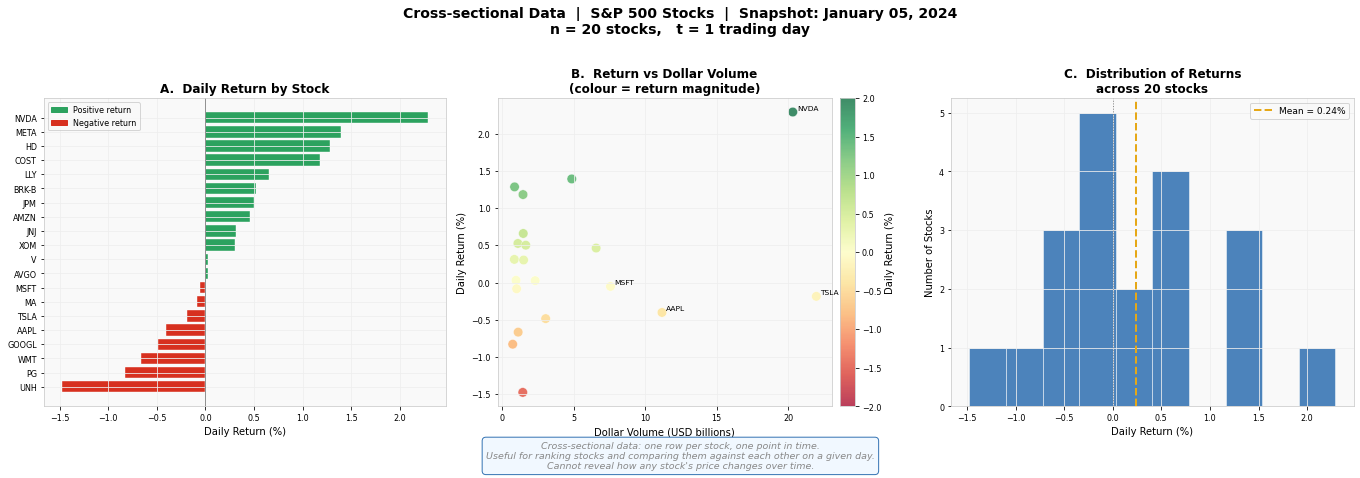

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
fig.suptitle(
    f'Cross-sectional Data  |  S&P 500 Stocks  |  Snapshot: {SNAP_DATE.strftime("%B %d, %Y")}\n'
    'n = 20 stocks,   t = 1 trading day',
    fontsize=14, fontweight='bold', y=1.02)

# ── A: horizontal bar — daily returns (green = positive, red = negative) ──
ax = axes[0]
sorted_ret  = cross['return_pct'].sort_values()
colors_bar  = [C_UP if v >= 0 else C_DOWN for v in sorted_ret]
ax.barh(sorted_ret.index, sorted_ret.values,
        color=colors_bar, edgecolor='white', linewidth=0.4)
ax.axvline(0, color=C_GRAY, lw=0.9)
ax.set_xlabel('Daily Return (%)')
ax.set_title('A.  Daily Return by Stock', fontweight='bold')
patch_up   = mpatches.Patch(color=C_UP,   label='Positive return')
patch_down = mpatches.Patch(color=C_DOWN, label='Negative return')
ax.legend(handles=[patch_up, patch_down], fontsize=8)

# ── B: scatter — dollar volume vs return, colour = return magnitude ────────
ax = axes[1]
sc = ax.scatter(
    cross['dollar_vol_B'],
    cross['return_pct'],
    s=90, alpha=0.75,
    c=cross['return_pct'], cmap='RdYlGn', vmin=-2, vmax=2,
    edgecolors='white', linewidth=0.5)
plt.colorbar(sc, ax=ax, label='Daily Return (%)', pad=0.02)
for tk in ['AAPL', 'MSFT', 'NVDA', 'TSLA']:
    if tk in cross.index:
        ax.annotate(tk,
                    (cross.loc[tk,'dollar_vol_B'], cross.loc[tk,'return_pct']),
                    fontsize=7.5, ha='left',
                    xytext=(4, 2), textcoords='offset points')
ax.set_xlabel('Dollar Volume (USD billions)')
ax.set_ylabel('Daily Return (%)')
ax.set_title('B.  Return vs Dollar Volume\n(colour = return magnitude)',
             fontweight='bold')

# ── C: histogram — distribution of returns across all 20 stocks ───────────
ax = axes[2]
ax.hist(cross['return_pct'].values, bins=10, color=C_BLUE,
        edgecolor='white', linewidth=0.6, alpha=0.8)
ax.axvline(cross['return_pct'].mean(), color=C_GOLD, lw=2.0, ls='--',
           label=f"Mean = {cross['return_pct'].mean():.2f}%")
ax.axvline(0, color=C_GRAY, lw=1.0, ls=':')
ax.set_xlabel('Daily Return (%)')
ax.set_ylabel('Number of Stocks')
ax.set_title('C.  Distribution of Returns\nacross 20 stocks', fontweight='bold')
ax.legend(fontsize=9)

note = (
    'Cross-sectional data: one row per stock, one point in time.\n'
    'Useful for ranking stocks and comparing them against each other on a given day.\n'
    'Cannot reveal how any stock\'s price changes over time.'
)
fig.text(0.5, -0.05, note, ha='center', fontsize=9.5, style='italic', color=C_GRAY,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F8FF',
                   edgecolor=C_BLUE, alpha=0.9))
plt.tight_layout()
plt.show()


---
## Block 2 — Time-series Data  (n = 1, t > 1)

**What it is:** One entity — the S&P 500 index — tracked every trading day
from January 2020 through December 2024.

| Dimension | Value |
|-----------|-------|
| Entities (n) | 1 index |
| Time points (t) | ~1,304 trading days |
| Key question | *How does the market evolve over time?* |

> **Three views of the same time series:**
> price level (trend), daily returns (volatility), rolling volatility (regime).


##### Build time-series features


In [6]:
# 30-day rolling annualised volatility
roll_vol = sp_ret.rolling(30).std() * np.sqrt(252) * 100

print(f'Time-series shape: {sp500.shape}  → n = 1 index, t = {len(sp500)} days')
display(pd.DataFrame({
    'SP500_price': sp500,
    'SP500_return_%': sp_ret*100,
    'Rolling_vol_%': roll_vol,
}).tail(8).round(3))


Time-series shape: (1256,)  → n = 1 index, t = 1256 days


,SP500_price,SP500_return_%,Rolling_vol_%
Date,,,
2024-12-18,5872.16,-2.949,13.745
2024-12-19,5867.08,-0.087,11.571
2024-12-20,5930.85,1.087,11.812
2024-12-23,5974.07,0.729,11.958
2024-12-24,6040.04,1.104,12.385
2024-12-26,6037.59,-0.041,12.351
2024-12-27,5970.84,-1.106,12.784
2024-12-30,5906.94,-1.070,13.042


##### Plot 2 — Time series: price, daily returns, rolling volatility


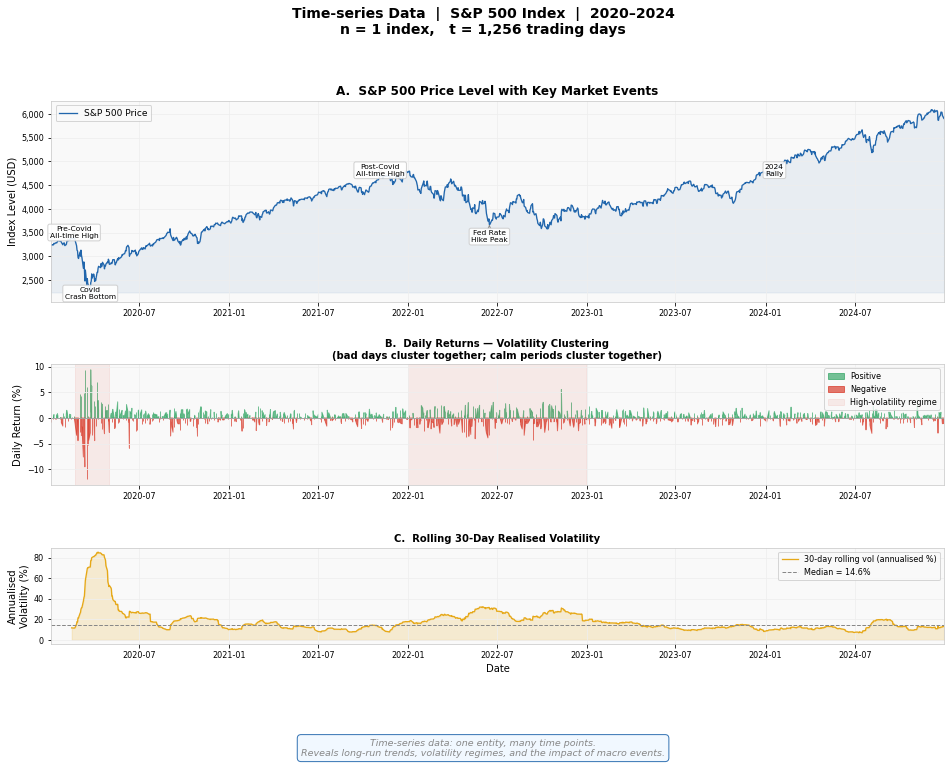

In [7]:
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(3, 1, figure=fig, hspace=0.45,
                        height_ratios=[2.5, 1.5, 1.2])
fig.suptitle(
    'Time-series Data  |  S&P 500 Index  |  2020–2024\n'
    f'n = 1 index,   t = {len(sp500):,} trading days',
    fontsize=14, fontweight='bold', y=1.01)

# ── A: price level with annotated macro events ────────────────────────────
ax = fig.add_subplot(gs[0])
ax.plot(sp500.index, sp500, color=C_BLUE, lw=1.3, label='S&P 500 Price')
ax.fill_between(sp500.index, sp500, sp500.min(), alpha=0.08, color=C_BLUE)

events = [
    ('2020-02-19', 3386, 'Pre-Covid\nAll-time High'),
    ('2020-03-23', 2100, 'Covid\nCrash Bottom'),
    ('2021-11-05', 4698, 'Post-Covid\nAll-time High'),
    ('2022-06-16', 3300, 'Fed Rate\nHike Peak'),
    ('2024-01-19', 4700, '2024\nRally'),
]
for ds, y_ann, lbl in events:
    xv = pd.Timestamp(ds)
    if xv in sp500.index:
        yv = sp500.loc[xv]
    else:
        yv = sp500.asof(xv)
    ax.annotate(lbl, xy=(xv, yv), xytext=(xv, y_ann),
                arrowprops=dict(arrowstyle='->', color=C_GRAY, lw=1.0),
                fontsize=7.5, ha='center', color='black',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                          edgecolor='#CCCCCC', alpha=0.9))
ax.set_ylabel('Index Level (USD)')
ax.set_title('A.  S&P 500 Price Level with Key Market Events', fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax.legend(fontsize=9)
ax.set_xlim(sp500.index[0], sp500.index[-1])

# ── B: daily returns — shows volatility clustering ────────────────────────
ax = fig.add_subplot(gs[1])
ax.fill_between(sp_ret.index, sp_ret*100, 0,
                where=sp_ret>=0, color=C_UP,   alpha=0.65, label='Positive')
ax.fill_between(sp_ret.index, sp_ret*100, 0,
                where=sp_ret<0,  color=C_DOWN, alpha=0.65, label='Negative')
ax.axhline(0, color=C_GRAY, lw=0.7)
# shade high-volatility regimes
ax.axvspan(pd.Timestamp('2020-02-20'), pd.Timestamp('2020-05-01'),
           alpha=0.08, color=C_DOWN, label='High-volatility regime')
ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'),
           alpha=0.08, color=C_DOWN)
ax.set_ylabel('Daily Return (%)')
ax.set_title('B.  Daily Returns — Volatility Clustering\n'
             '(bad days cluster together; calm periods cluster together)',
             fontweight='bold', fontsize=10)
ax.legend(fontsize=8, loc='upper right')
ax.set_xlim(sp_ret.index[0], sp_ret.index[-1])

# ── C: rolling 30-day realised volatility ────────────────────────────────
ax = fig.add_subplot(gs[2])
ax.plot(roll_vol.index, roll_vol, color=C_GOLD, lw=1.3,
        label='30-day rolling vol (annualised %)')
ax.fill_between(roll_vol.index, roll_vol, 0, alpha=0.18, color=C_GOLD)
ax.axhline(roll_vol.median(), color=C_GRAY, lw=1.0, ls='--',
           label=f'Median = {roll_vol.median():.1f}%')
ax.set_ylabel('Annualised\nVolatility (%)')
ax.set_title('C.  Rolling 30-Day Realised Volatility', fontweight='bold', fontsize=10)
ax.legend(fontsize=8)
ax.set_xlim(roll_vol.index[0], roll_vol.index[-1])
ax.set_xlabel('Date')

note = (
    'Time-series data: one entity, many time points.\n'
    'Reveals long-run trends, volatility regimes, and the impact of macro events.'
)
fig.text(0.5, -0.03, note, ha='center', fontsize=9.5, style='italic', color=C_GRAY,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F8FF',
                   edgecolor=C_BLUE, alpha=0.9))
plt.show()


---
## Block 3 — Panel Data  (n > 1, t > 1)

**What it is:** Multiple stocks tracked over the full 5-year period.
This gives us both the cross-sectional breadth of Block 1 and the
time-series depth of Block 2 — simultaneously.

| Dimension | Value |
|-----------|-------|
| Entities (n) | 10 stocks |
| Time points (t) | ~1,304 trading days |
| Total observations | ~13,040 rows |
| Key question | *How does each stock perform — and how do they compare over time?* |


##### Build panel features


In [8]:
px10   = prices[TICKERS_10]
ret10  = rets[TICKERS_10]

# normalise all prices to 100 on day 1 (makes comparison fair)
px_norm = px10.div(px10.iloc[0]) * 100

# annual returns: compound daily returns within each calendar year
ret10_y = ret10.copy()
ret10_y['year'] = ret10.index.year
ann_ret = (
    ret10_y.groupby('year')[TICKERS_10]
    .apply(lambda df: (1 + df).prod() - 1) * 100
)

# full-period daily return correlation matrix
corr = ret10.corr()

print(f'Panel shape   : {ret10.shape}   → n = {len(TICKERS_10)} stocks, t = {len(ret10)} days')
print(f'Annual returns (%):')
display(ann_ret.round(1))


Panel shape   : (1256, 10)   → n = 10 stocks, t = 1256 days
Annual returns (%):


Ticker,AAPL,MSFT,NVDA,AMZN,GOOGL,META,TSLA,JPM,V,XOM
year,,,,,,,,,,
2020,78.2,39.9,118.0,71.6,28.1,30.2,720.1,-6.7,15.2,-37.2
2021,34.6,52.5,125.5,2.4,65.3,23.1,49.8,27.7,-0.3,57.6
2022,-26.4,-28.0,-50.3,-49.6,-39.1,-64.2,-65.0,-12.6,-3.4,87.4
2023,49.0,58.2,239.0,80.9,58.3,194.1,101.7,30.6,26.3,-6.3
2024,31.6,13.8,177.7,45.6,37.4,67.7,68.0,44.1,22.0,9.4


##### Plot 3 — Panel: normalised prices, annual return heatmap, correlation matrix


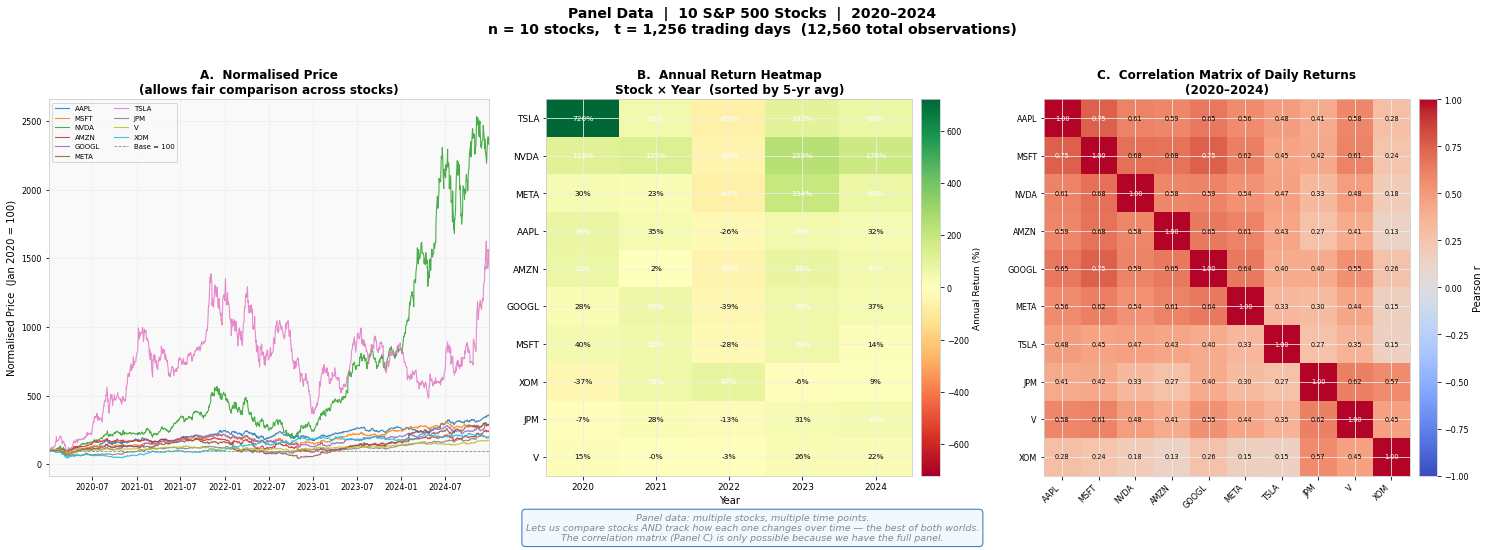

In [9]:
PALETTE = {
    'AAPL':'#1f77b4', 'MSFT':'#ff7f0e', 'NVDA':'#2ca02c', 'AMZN':'#d62728',
    'GOOGL':'#9467bd','META':'#8c564b', 'TSLA':'#e377c2', 'JPM':'#7f7f7f',
    'V':'#bcbd22',    'XOM':'#17becf',
}

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
fig.suptitle(
    'Panel Data  |  10 S&P 500 Stocks  |  2020–2024\n'
    f'n = 10 stocks,   t = {len(ret10):,} trading days  ({ret10.shape[0]*ret10.shape[1]:,} total observations)',
    fontsize=14, fontweight='bold', y=1.02)

# ── A: all 10 stocks — normalised price (base = 100) ─────────────────────
ax = axes[0]
for tk in TICKERS_10:
    ax.plot(px_norm.index, px_norm[tk],
            color=PALETTE[tk], lw=1.1, alpha=0.85, label=tk)
ax.axhline(100, color=C_GRAY, lw=0.8, ls='--', label='Base = 100')
ax.set_ylabel('Normalised Price  (Jan 2020 = 100)')
ax.set_title('A.  Normalised Price\n(allows fair comparison across stocks)',
             fontweight='bold')
ax.legend(fontsize=7, ncol=2, loc='upper left')
ax.set_xlim(px_norm.index[0], px_norm.index[-1])
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%d'))

# ── B: heatmap — annual return by stock × year ────────────────────────────
ax = axes[1]
avg_order = ann_ret.mean().sort_values(ascending=False).index.tolist()
heat      = ann_ret[avg_order]
vmax      = max(abs(heat.values.min()), abs(heat.values.max()))
im = ax.imshow(heat.T.values, aspect='auto', cmap='RdYlGn',
               vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(heat.index)))
ax.set_xticklabels(heat.index.astype(str), fontsize=9)
ax.set_yticks(range(len(avg_order)))
ax.set_yticklabels(avg_order, fontsize=9)
for i in range(len(heat.index)):
    for j, tk in enumerate(avg_order):
        val = heat.loc[heat.index[i], tk]
        ax.text(i, j, f'{val:.0f}%', ha='center', va='center',
                fontsize=7.5,
                color='black' if abs(val) < 40 else 'white')
cb = plt.colorbar(im, ax=ax, pad=0.02)
cb.set_label('Annual Return (%)', fontsize=9)
ax.set_title('B.  Annual Return Heatmap\nStock × Year  (sorted by 5-yr avg)',
             fontweight='bold')
ax.set_xlabel('Year')

# ── C: correlation matrix of daily returns ────────────────────────────────
ax = axes[2]
im2 = ax.imshow(corr.values, aspect='auto', cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(TICKERS_10)))
ax.set_xticklabels(TICKERS_10, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(TICKERS_10)))
ax.set_yticklabels(TICKERS_10, fontsize=8)
for i in range(len(TICKERS_10)):
    for j in range(len(TICKERS_10)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}',
                ha='center', va='center', fontsize=6.5,
                color='black' if abs(corr.values[i,j]) < 0.7 else 'white')
plt.colorbar(im2, ax=ax, label='Pearson r', pad=0.02)
ax.set_title('C.  Correlation Matrix of Daily Returns\n(2020–2024)',
             fontweight='bold')

note = (
    'Panel data: multiple stocks, multiple time points.\n'
    'Lets us compare stocks AND track how each one changes over time — the best of both worlds.\n'
    'The correlation matrix (Panel C) is only possible because we have the full panel.'
)
fig.text(0.5, -0.04, note, ha='center', fontsize=9.5, style='italic', color=C_GRAY,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F8FF',
                   edgecolor=C_BLUE, alpha=0.9))
plt.tight_layout()
plt.show()


---
## Block 4 — Summary: What Makes Each Structure Different?

The dot grid below shows *which cells of the data matrix are filled*
for each data type.
Blue dots = observations you have.  Grey dots = observations you don't.


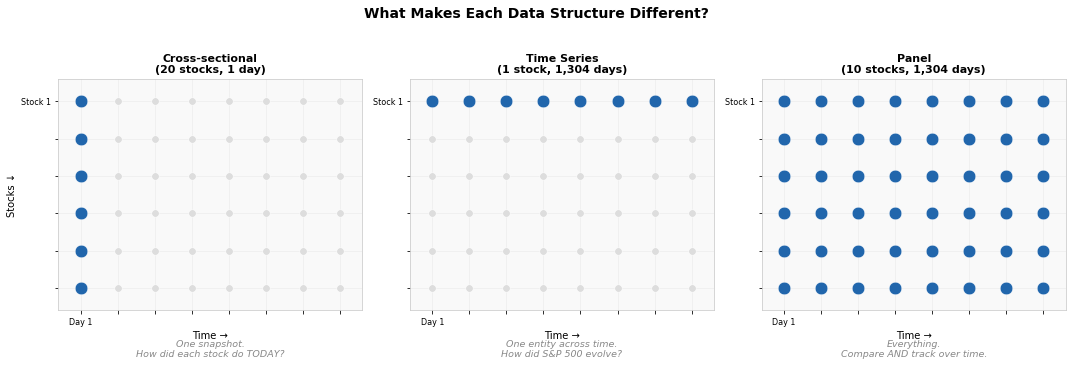

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('What Makes Each Data Structure Different?',
             fontsize=14, fontweight='bold', y=1.03)

def draw_grid(ax, n_rows, n_cols, fill_rows=None, fill_cols=None,
              label_x='', label_y='', title='', note=''):
    for r in range(n_rows):
        for c in range(n_cols):
            obs = (
                (fill_rows is None or r in fill_rows) and
                (fill_cols is None or c in fill_cols)
            )
            ax.scatter(c, -r, s=160 if obs else 55, zorder=3,
                       color=C_BLUE if obs else '#DDDDDD',
                       edgecolors='white', linewidth=0.5)
    ax.set_xlim(-0.6, n_cols - 0.4)
    ax.set_ylim(-n_rows + 0.4, 0.6)
    ax.set_xlabel(label_x, fontsize=10)
    ax.set_ylabel(label_y, fontsize=10)
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_xticks(range(n_cols))
    ax.set_yticks(range(0, -n_rows, -1))
    ax.set_xticklabels(['Day 1' if i==0 else '' for i in range(n_cols)], fontsize=8)
    ax.set_yticklabels(['Stock 1' if i==0 else '' for i in range(n_rows)], fontsize=8)
    ax.text(0.5, -0.20, note, transform=ax.transAxes,
            ha='center', fontsize=9.5, style='italic', color=C_GRAY)

NR, NC = 6, 8

draw_grid(axes[0], NR, NC, fill_cols=[0],
          label_x='Time →', label_y='Stocks ↓',
          title='Cross-sectional\n(20 stocks, 1 day)',
          note='One snapshot.\nHow did each stock do TODAY?')

draw_grid(axes[1], NR, NC, fill_rows=[0],
          label_x='Time →', label_y='',
          title='Time Series\n(1 stock, 1,304 days)',
          note='One entity across time.\nHow did S&P 500 evolve?')

draw_grid(axes[2], NR, NC,
          label_x='Time →', label_y='',
          title='Panel\n(10 stocks, 1,304 days)',
          note='Everything.\nCompare AND track over time.')

plt.tight_layout()
plt.show()


---
## Dataset Structure Summary


In [11]:
print('DATASET STRUCTURE SUMMARY')
print('─' * 55)
print(f'Cross-sectional : n = {len(cross):>2} stocks,  t =    1 day')
print(f'Time series     : n =  1 index,   t = {len(sp500):,} days')
print(f'Panel           : n = {len(TICKERS_10):>2} stocks,  t = {len(ret10):,} days'
      f'  ({len(ret10)*len(TICKERS_10):,} total rows)')
print()
print('Key takeaway')
print('─' * 55)
print('Cross-sectional → compare across stocks at one moment.')
print('Time series     → follow one stock / index across time.')
print('Panel           → do both simultaneously.')
print()
print('For forecasting: we almost always need TIME in our data.')
print('Cross-sectional alone cannot tell us where a stock is headed.')


DATASET STRUCTURE SUMMARY
───────────────────────────────────────────────────────
Cross-sectional : n = 20 stocks,  t =    1 day
Time series     : n =  1 index,   t = 1,256 days
Panel           : n = 10 stocks,  t = 1,256 days  (12,560 total rows)

Key takeaway
───────────────────────────────────────────────────────
Cross-sectional → compare across stocks at one moment.
Time series     → follow one stock / index across time.
Panel           → do both simultaneously.

For forecasting: we almost always need TIME in our data.
Cross-sectional alone cannot tell us where a stock is headed.


In [12]:
import os

# Create directory if it doesn't exist
fig_dir = "lecture1_figures"
os.makedirs(fig_dir, exist_ok=True)

# Block 1 — Cross-sectional: returns, return vs dollar volume, and distribution
fig1, axes1 = plt.subplots(1, 3, figsize=(19, 6))
fig1.suptitle(
    f'Cross-sectional Data  |  S&P 500 Stocks  |  Snapshot: {SNAP_DATE.strftime("%B %d, %Y")}\n'
    'n = 20 stocks,   t = 1 trading day',
    fontsize=14, fontweight='bold', y=1.02)

# A: horizontal bar — daily returns
ax = axes1[0]
sorted_ret = cross['return_pct'].sort_values()
colors_bar = [C_UP if v >= 0 else C_DOWN for v in sorted_ret]
ax.barh(sorted_ret.index, sorted_ret.values, color=colors_bar, edgecolor='white', linewidth=0.4)
ax.axvline(0, color=C_GRAY, lw=0.9)
ax.set_xlabel('Daily Return (%)')
ax.set_title('A.  Daily Return by Stock', fontweight='bold')
patch_up = mpatches.Patch(color=C_UP, label='Positive return')
patch_down = mpatches.Patch(color=C_DOWN, label='Negative return')
ax.legend(handles=[patch_up, patch_down], fontsize=8)

# B: scatter — dollar volume vs return
ax = axes1[1]
sc = ax.scatter(
    cross['dollar_vol_B'],
    cross['return_pct'],
    s=90, alpha=0.75,
    c=cross['return_pct'], cmap='RdYlGn', vmin=-2, vmax=2,
    edgecolors='white', linewidth=0.5)
plt.colorbar(sc, ax=ax, label='Daily Return (%)', pad=0.02)
for tk in ['AAPL', 'MSFT', 'NVDA', 'TSLA']:
    if tk in cross.index:
        ax.annotate(tk,
                    (cross.loc[tk,'dollar_vol_B'], cross.loc[tk,'return_pct']),
                    fontsize=7.5, ha='left',
                    xytext=(4, 2), textcoords='offset points')
ax.set_xlabel('Dollar Volume (USD billions)')
ax.set_ylabel('Daily Return (%)')
ax.set_title('B.  Return vs Dollar Volume\n(colour = return magnitude)', fontweight='bold')

# C: histogram — distribution of returns
ax = axes1[2]
ax.hist(cross['return_pct'].values, bins=10, color=C_BLUE,
        edgecolor='white', linewidth=0.6, alpha=0.8)
ax.axvline(cross['return_pct'].mean(), color=C_GOLD, lw=2.0, ls='--',
           label=f"Mean = {cross['return_pct'].mean():.2f}%")
ax.axvline(0, color=C_GRAY, lw=1.0, ls=':')
ax.set_xlabel('Daily Return (%)')
ax.set_ylabel('Number of Stocks')
ax.set_title('C.  Distribution of Returns\nacross 20 stocks', fontweight='bold')
ax.legend(fontsize=9)

note = (
    'Cross-sectional data: one row per stock, one point in time.\n'
    'Useful for ranking stocks and comparing them against each other on a given day.\n'
    'Cannot reveal how any stock\'s price changes over time.'
)
fig1.text(0.5, -0.05, note, ha='center', fontsize=9.5, style='italic', color=C_GRAY,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F8FF',
                   edgecolor=C_BLUE, alpha=0.9))
plt.tight_layout()
fig1.savefig(os.path.join(fig_dir, "block1_cross_sectional.png"), bbox_inches='tight')
plt.close(fig1)

# Block 2 — Time series: price, daily returns, rolling volatility
fig2 = plt.figure(figsize=(16, 10))
gs2 = gridspec.GridSpec(3, 1, figure=fig2, hspace=0.45, height_ratios=[2.5, 1.5, 1.2])
fig2.suptitle(
    'Time-series Data  |  S&P 500 Index  |  2020–2024\n'
    f'n = 1 index,   t = {len(sp500):,} trading days',
    fontsize=14, fontweight='bold', y=1.01)

# A: price level
ax = fig2.add_subplot(gs2[0])
ax.plot(sp500.index, sp500, color=C_BLUE, lw=1.3, label='S&P 500 Price')
ax.fill_between(sp500.index, sp500, sp500.min(), alpha=0.08, color=C_BLUE)
events = [
    ('2020-02-19', 3386, 'Pre-Covid\nAll-time High'),
    ('2020-03-23', 2100, 'Covid\nCrash Bottom'),
    ('2021-11-05', 4698, 'Post-Covid\nAll-time High'),
    ('2022-06-16', 3300, 'Fed Rate\nHike Peak'),
    ('2024-01-19', 4700, '2024\nRally'),
]
for ds, y_ann, lbl in events:
    xv = pd.Timestamp(ds)
    if xv in sp500.index:
        yv = sp500.loc[xv]
    else:
        yv = sp500.asof(xv)
    ax.annotate(lbl, xy=(xv, yv), xytext=(xv, y_ann),
                arrowprops=dict(arrowstyle='->', color=C_GRAY, lw=1.0),
                fontsize=7.5, ha='center', color='black',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                          edgecolor='#CCCCCC', alpha=0.9))
ax.set_ylabel('Index Level (USD)')
ax.set_title('A.  S&P 500 Price Level with Key Market Events', fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax.legend(fontsize=9)
ax.set_xlim(sp500.index[0], sp500.index[-1])

# B: daily returns
ax = fig2.add_subplot(gs2[1])
ax.fill_between(sp_ret.index, sp_ret*100, 0,
                where=sp_ret>=0, color=C_UP,   alpha=0.65, label='Positive')
ax.fill_between(sp_ret.index, sp_ret*100, 0,
                where=sp_ret<0,  color=C_DOWN, alpha=0.65, label='Negative')
ax.axhline(0, color=C_GRAY, lw=0.7)
ax.axvspan(pd.Timestamp('2020-02-20'), pd.Timestamp('2020-05-01'),
           alpha=0.08, color=C_DOWN, label='High-volatility regime')
ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'),
           alpha=0.08, color=C_DOWN)
ax.set_ylabel('Daily Return (%)')
ax.set_title('B.  Daily Returns — Volatility Clustering\n'
             '(bad days cluster together; calm periods cluster together)',
             fontweight='bold', fontsize=10)
ax.legend(fontsize=8, loc='upper right')
ax.set_xlim(sp_ret.index[0], sp_ret.index[-1])

# C: rolling 30-day realised volatility
ax = fig2.add_subplot(gs2[2])
ax.plot(roll_vol.index, roll_vol, color=C_GOLD, lw=1.3,
        label='30-day rolling vol (annualised %)')
ax.fill_between(roll_vol.index, roll_vol, 0, alpha=0.18, color=C_GOLD)
ax.axhline(roll_vol.median(), color=C_GRAY, lw=1.0, ls='--',
           label=f'Median = {roll_vol.median():.1f}%')
ax.set_ylabel('Annualised\nVolatility (%)')
ax.set_title('C.  Rolling 30-Day Realised Volatility', fontweight='bold', fontsize=10)
ax.legend(fontsize=8)
ax.set_xlim(roll_vol.index[0], roll_vol.index[-1])
ax.set_xlabel('Date')

note = (
    'Time-series data: one entity, many time points.\n'
    'Reveals long-run trends, volatility regimes, and the impact of macro events.'
)
fig2.text(0.5, -0.03, note, ha='center', fontsize=9.5, style='italic', color=C_GRAY,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F8FF',
                   edgecolor=C_BLUE, alpha=0.9))
fig2.tight_layout()
fig2.savefig(os.path.join(fig_dir, "block2_time_series.png"), bbox_inches='tight')
plt.close(fig2)

# Block 3 — Panel: normalised prices, annual return heatmap, correlation matrix
PALETTE = {
    'AAPL':'#1f77b4', 'MSFT':'#ff7f0e', 'NVDA':'#2ca02c', 'AMZN':'#d62728',
    'GOOGL':'#9467bd','META':'#8c564b', 'TSLA':'#e377c2', 'JPM':'#7f7f7f',
    'V':'#bcbd22',    'XOM':'#17becf',
}
fig3, axes3 = plt.subplots(1, 3, figsize=(21, 7))
fig3.suptitle(
    'Panel Data  |  10 S&P 500 Stocks  |  2020–2024\n'
    f'n = 10 stocks,   t = {len(ret10):,} trading days  ({ret10.shape[0]*ret10.shape[1]:,} total observations)',
    fontsize=14, fontweight='bold', y=1.02)

# A: all 10 stocks — normalised price (base = 100)
ax = axes3[0]
for tk in TICKERS_10:
    ax.plot(px_norm.index, px_norm[tk],
            color=PALETTE[tk], lw=1.1, alpha=0.85, label=tk)
ax.axhline(100, color=C_GRAY, lw=0.8, ls='--', label='Base = 100')
ax.set_ylabel('Normalised Price  (Jan 2020 = 100)')
ax.set_title('A.  Normalised Price\n(allows fair comparison across stocks)',
             fontweight='bold')
ax.legend(fontsize=7, ncol=2, loc='upper left')
ax.set_xlim(px_norm.index[0], px_norm.index[-1])
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%d'))

# B: heatmap — annual return by stock × year
ax = axes3[1]
avg_order = ann_ret.mean().sort_values(ascending=False).index.tolist()
heat = ann_ret[avg_order]
vmax = max(abs(heat.values.min()), abs(heat.values.max()))
im = ax.imshow(heat.T.values, aspect='auto', cmap='RdYlGn',
               vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(heat.index)))
ax.set_xticklabels(heat.index.astype(str), fontsize=9)
ax.set_yticks(range(len(avg_order)))
ax.set_yticklabels(avg_order, fontsize=9)
for i in range(len(heat.index)):
    for j, tk in enumerate(avg_order):
        val = heat.loc[heat.index[i], tk]
        ax.text(i, j, f'{val:.0f}%', ha='center', va='center',
                fontsize=7.5,
                color='black' if abs(val) < 40 else 'white')
cb = plt.colorbar(im, ax=ax, pad=0.02)
cb.set_label('Annual Return (%)', fontsize=9)
ax.set_title('B.  Annual Return Heatmap\nStock × Year  (sorted by 5-yr avg)',
             fontweight='bold')
ax.set_xlabel('Year')

# C: correlation matrix of daily returns
ax = axes3[2]
im2 = ax.imshow(corr.values, aspect='auto', cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(TICKERS_10)))
ax.set_xticklabels(TICKERS_10, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(TICKERS_10)))
ax.set_yticklabels(TICKERS_10, fontsize=8)
for i in range(len(TICKERS_10)):
    for j in range(len(TICKERS_10)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}',
                ha='center', va='center', fontsize=6.5,
                color='black' if abs(corr.values[i,j]) < 0.7 else 'white')
plt.colorbar(im2, ax=ax, label='Pearson r', pad=0.02)
ax.set_title('C.  Correlation Matrix of Daily Returns\n(2020–2024)',
             fontweight='bold')

note = (
    'Panel data: multiple stocks, multiple time points.\n'
    'Lets us compare stocks AND track how each one changes over time — the best of both worlds.\n'
    'The correlation matrix (Panel C) is only possible because we have the full panel.'
)
fig3.text(0.5, -0.04, note, ha='center', fontsize=9.5, style='italic', color=C_GRAY,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F8FF',
                   edgecolor=C_BLUE, alpha=0.9))
plt.tight_layout()
fig3.savefig(os.path.join(fig_dir, "block3_panel.png"), bbox_inches='tight')
plt.close(fig3)

# Block 4 — Dot grid summary
fig4, axes4 = plt.subplots(1, 3, figsize=(15, 5))
fig4.suptitle('What Makes Each Data Structure Different?',
             fontsize=14, fontweight='bold', y=1.03)

def draw_grid(ax, n_rows, n_cols, fill_rows=None, fill_cols=None,
              label_x='', label_y='', title='', note=''):
    for r in range(n_rows):
        for c in range(n_cols):
            obs = (
                (fill_rows is None or r in fill_rows) and
                (fill_cols is None or c in fill_cols)
            )
            ax.scatter(c, -r, s=160 if obs else 55, zorder=3,
                       color=C_BLUE if obs else '#DDDDDD',
                       edgecolors='white', linewidth=0.5)
    ax.set_xlim(-0.6, n_cols - 0.4)
    ax.set_ylim(-n_rows + 0.4, 0.6)
    ax.set_xlabel(label_x, fontsize=10)
    ax.set_ylabel(label_y, fontsize=10)
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_xticks(range(n_cols))
    ax.set_yticks(range(0, -n_rows, -1))
    ax.set_xticklabels(['Day 1' if i==0 else '' for i in range(n_cols)], fontsize=8)
    ax.set_yticklabels(['Stock 1' if i==0 else '' for i in range(n_rows)], fontsize=8)
    ax.text(0.5, -0.20, note, transform=ax.transAxes,
            ha='center', fontsize=9.5, style='italic', color=C_GRAY)

NR, NC = 6, 8
draw_grid(axes4[0], NR, NC, fill_cols=[0],
          label_x='Time →', label_y='Stocks ↓',
          title='Cross-sectional\n(20 stocks, 1 day)',
          note='One snapshot.\nHow did each stock do TODAY?')
draw_grid(axes4[1], NR, NC, fill_rows=[0],
          label_x='Time →', label_y='',
          title='Time Series\n(1 stock, 1,304 days)',
          note='One entity across time.\nHow did S&P 500 evolve?')
draw_grid(axes4[2], NR, NC,
          label_x='Time →', label_y='',
          title='Panel\n(10 stocks, 1,304 days)',
          note='Everything.\nCompare AND track over time.')

plt.tight_layout()
fig4.savefig(os.path.join(fig_dir, "block4_dot_grid.png"), bbox_inches='tight')
plt.close(fig4)

## Transition to Lecture 1.2

The next section builds on this idea and moves to **Information Set, Conditional Expectation, and Error Term**.


---

# Lecture 1.2 - Information Set, Conditional Expectation, and Error Term

This section connects forecasting code to the information set: what is known at the forecast date, what the model predicts, and what remains as error.

Source notebook: `Lecture 1.2 information_set.ipynb`


---
## Setup — Rebuild the AR(2) Model from Lecture 1

We reuse the same data and the same model.
Run this cell first — everything below depends on it.


In [13]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
from sklearn.linear_model import LinearRegression
import warnings; warnings.filterwarnings('ignore')

# ── palette ──────────────────────────────────────────────────────────
C_ACT  = '#2166AC'    # actual series
C_FIT  = '#D6604D'    # fitted / conditional expectation
C_ERR  = '#888888'    # error term (neutral)
C_UP   = '#2ca25f'    # positive
C_DOWN = '#d7301f'    # negative
C_GOLD = '#E6A817'    # regime highlight

plt.rcParams.update({
    'figure.facecolor':'white',   'axes.facecolor':'#F9F9F9',
    'axes.edgecolor':'#CCCCCC',   'axes.grid':True,
    'grid.color':'#EEEEEE',       'grid.linewidth':0.8,
    'font.family':'DejaVu Sans',
    'axes.titlesize':12,          'axes.labelsize':10,
    'xtick.labelsize':8,          'ytick.labelsize':8,
})


In [14]:
# ── download S&P 500 ─────────────────────────────────────────────────
sp500  = yf.download('^GSPC', start='2020-01-01', end='2024-12-31',
                     auto_adjust=True, progress=False)['Close'].squeeze().dropna()
dates  = sp500.index
sp_ret = sp500.pct_change().dropna()

# ── build lag dataset ────────────────────────────────────────────────
lag_df = pd.DataFrame({
    'yt':   sp500,
    'yt_1': sp500.shift(1),
    'yt_2': sp500.shift(2),
}).dropna()

X      = lag_df[['yt_1','yt_2']].values
y      = lag_df['yt'].values
reg    = LinearRegression().fit(X, y)
fitted = reg.predict(X)           # E[ S_t | Ω_t ]
resid  = y - fitted               # ε_t
sigma  = resid.std()

print('AR(2) on S&P 500 price level')
print(f'  β₀ = {reg.intercept_:.4f}')
print(f'  β₁ = {reg.coef_[0]:.6f}   (on S_{{t-1}})')
print(f'  β₂ = {reg.coef_[1]:.6f}   (on S_{{t-2}})')
print(f'  R² = {reg.score(X,y):.6f}')
print(f'  σ  = {sigma:.2f} USD   (std of residuals = spread of ε_t)')


AR(2) on S&P 500 price level
  β₀ = 4.8778
  β₁ = 0.912199   (on S_{t-1})
  β₂ = 0.087200   (on S_{t-2})
  R² = 0.995982
  σ  = 48.53 USD   (std of residuals = spread of ε_t)


---
## Section 1 — Information Set  Ω_t

**Definition:**
> Ω_t is the complete collection of everything you can actually observe
> *up to and including* time t.

Three things to keep in mind:

1. **Hard time boundary** — anything after t is outside Ω_t,
   even if it is certain to happen.
2. **'Observable' is the key word** — not 'important', not 'relevant'.
   If you cannot get the data, it is not in Ω_t.
3. **Your model uses only a small slice of Ω_t** — the AR(2) uses
   only { S_{t-1}, S_{t-2} }, which is Tier 1 below.
   The rest of Ω_t is available but your model ignores it.


Forecasting from: 2021-12-29


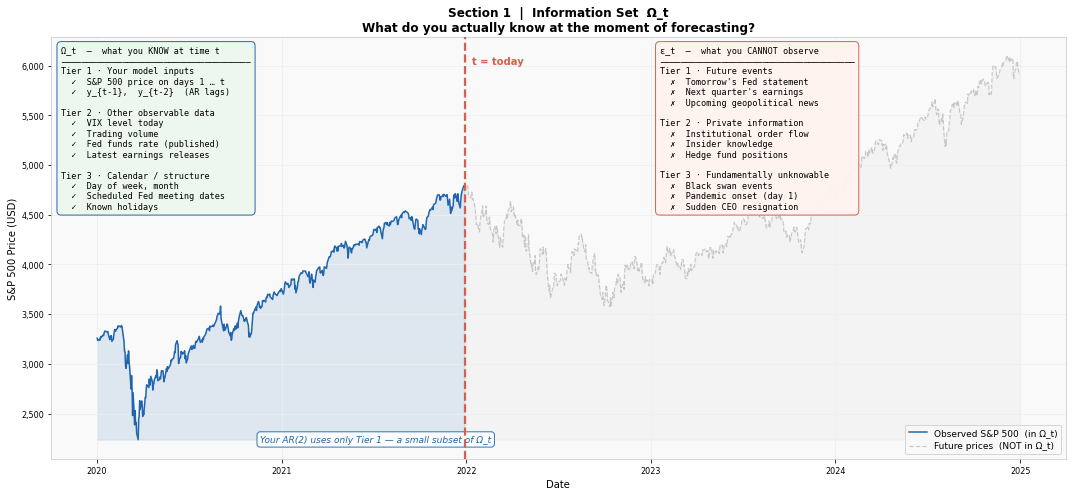

In [15]:
TODAY_IDX = 500                         # standing at trading day 500
today     = lag_df.index[TODAY_IDX]
print(f'Forecasting from: {today.date()}')

fig, ax = plt.subplots(figsize=(15, 7))

# ── known history ─────────────────────────────────────────────────────
known_px = sp500.iloc[:TODAY_IDX+2]
ax.fill_between(known_px.index, known_px, known_px.min(),
                alpha=0.12, color=C_ACT)
ax.plot(known_px.index, known_px, color=C_ACT, lw=1.5,
        label='Observed S&P 500  (in Ω_t)')

# ── unknown future ────────────────────────────────────────────────────
future_px = sp500.iloc[TODAY_IDX+2:]
ax.fill_between(future_px.index, future_px, known_px.min(),
                alpha=0.05, color=C_ERR)
ax.plot(future_px.index, future_px, color=C_ERR, lw=1.2,
        ls='--', alpha=0.4, label='Future prices  (NOT in Ω_t)')

# ── 'today' dividing line ─────────────────────────────────────────────
ax.axvline(today, color=C_FIT, lw=2.2, ls='--', zorder=5)
ax.text(today, ax.get_ylim()[1]*0.97, '  t = today',
        color=C_FIT, fontsize=10, fontweight='bold', va='top')

# ── what IS in Omega_t ────────────────────────────────────────────────
omega_txt = (
    'Ω_t  —  what you KNOW at time t\n'
    '─────────────────────────────────────\n'
    'Tier 1 · Your model inputs\n'
    '  ✓  S&P 500 price on days 1 … t\n'
    '  ✓  y_{t-1},  y_{t-2}  (AR lags)\n\n'
    'Tier 2 · Other observable data\n'
    '  ✓  VIX level today\n'
    '  ✓  Trading volume\n'
    '  ✓  Fed funds rate (published)\n'
    '  ✓  Latest earnings releases\n\n'
    'Tier 3 · Calendar / structure\n'
    '  ✓  Day of week, month\n'
    '  ✓  Scheduled Fed meeting dates\n'
    '  ✓  Known holidays'
)
ax.text(0.01, 0.98, omega_txt, transform=ax.transAxes,
        fontsize=8.5, va='top', family='monospace',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#EEF7EE',
                  edgecolor=C_ACT, alpha=0.97))

# ── what is NOT in Omega_t ────────────────────────────────────────────
unobs_txt = (
    'ε_t  —  what you CANNOT observe\n'
    '──────────────────────────────────────\n'
    'Tier 1 · Future events\n'
    '  ✗  Tomorrow\'s Fed statement\n'
    '  ✗  Next quarter\'s earnings\n'
    '  ✗  Upcoming geopolitical news\n\n'
    'Tier 2 · Private information\n'
    '  ✗  Institutional order flow\n'
    '  ✗  Insider knowledge\n'
    '  ✗  Hedge fund positions\n\n'
    'Tier 3 · Fundamentally unknowable\n'
    '  ✗  Black swan events\n'
    '  ✗  Pandemic onset (day 1)\n'
    '  ✗  Sudden CEO resignation'
)
ax.text(0.60, 0.98, unobs_txt, transform=ax.transAxes,
        fontsize=8.5, va='top', family='monospace',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#FFF3EE',
                  edgecolor=C_FIT, alpha=0.97))

# ── AR(2) scope note ──────────────────────────────────────────────────
ax.text(0.32, 0.04,
        'Your AR(2) uses only Tier 1 — a small subset of Ω_t',
        transform=ax.transAxes, fontsize=9, ha='center',
        style='italic', color=C_ACT,
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white',
                  edgecolor=C_ACT, alpha=0.9))

ax.set_ylabel('S&P 500 Price (USD)')
ax.set_xlabel('Date')
ax.set_title(
    'Section 1  |  Information Set  Ω_t\n'
    'What do you actually know at the moment of forecasting?',
    fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


---
## Section 2 — What Falls into the Error Term?

ε_t is not random noise invented by statisticians.
**It is real — it has real causes.** We just do not have data on those causes.

There are three categories of things that end up in ε_t:

| Category | Description | Example | Can we fix it? |
|----------|-------------|---------|----------------|
| **Cat 1** | Information existed and was in Ω_t — but not in *your* model | Inflation data, VIX | **Yes** — add it as a predictor |
| **Cat 2** | Information existed but nobody had it at time t | Pandemic on day 1 | No (at the time) |
| **Cat 3** | Fundamentally unforecastable | Random geopolitical shock | Never |

> **Key implication:** A large ε_t does not automatically mean a bad model.
> It might mean an extraordinary event occurred.
> Conversely, a small ε_t might mean Cat 1 problems — your model is leaving
> usable information on the table.


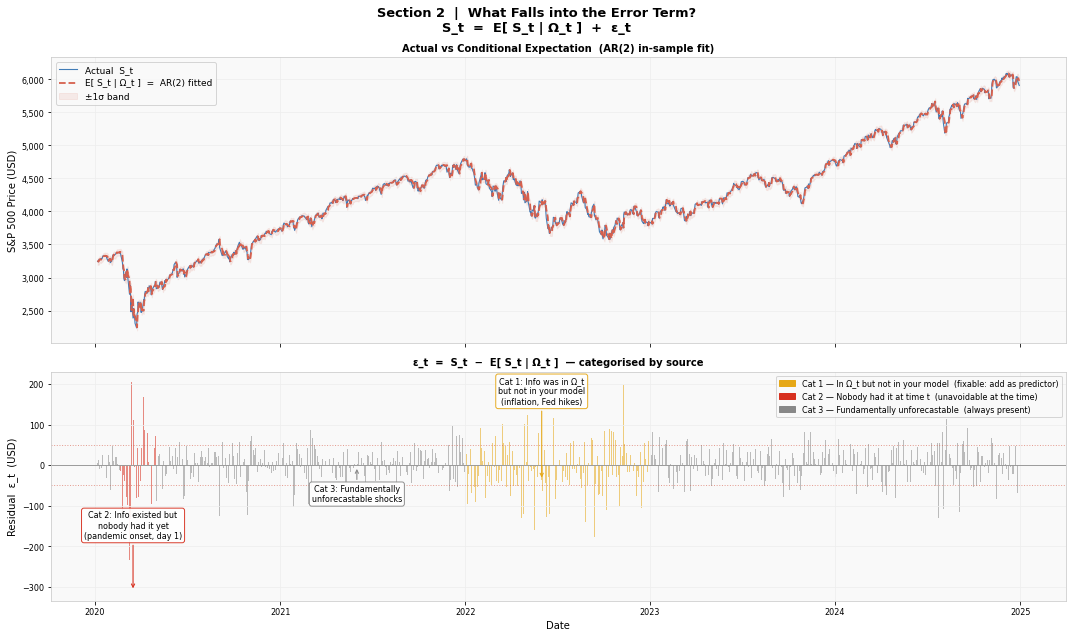

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True,
                         gridspec_kw={'height_ratios': [2.5, 2]})
fig.suptitle(
    'Section 2  |  What Falls into the Error Term?\n'
    'S_t  =  E[ S_t | Ω_t ]  +  ε_t',
    fontweight='bold', fontsize=13)

# ── top panel: actual vs conditional expectation ──────────────────────
ax = axes[0]
ax.plot(lag_df.index, y, color=C_ACT, lw=1.1, alpha=0.85,
        label='Actual  S_t')
ax.plot(lag_df.index, fitted, color=C_FIT, lw=1.8, ls='--',
        label='E[ S_t | Ω_t ]  =  AR(2) fitted')
ax.fill_between(lag_df.index, fitted-sigma, fitted+sigma,
                alpha=0.10, color=C_FIT, label='±1σ band')
ax.set_ylabel('S&P 500 Price (USD)')
ax.set_title('Actual vs Conditional Expectation  (AR(2) in-sample fit)',
             fontsize=10, fontweight='bold')
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

# ── bottom panel: residuals coloured by category ──────────────────────
ax = axes[1]

cat_colors = []
for d, r in zip(lag_df.index, resid):
    if pd.Timestamp('2020-02-20') <= d <= pd.Timestamp('2020-04-30'):
        cat_colors.append(C_DOWN)   # Cat 2: nobody had it
    elif pd.Timestamp('2022-01-01') <= d <= pd.Timestamp('2022-12-31'):
        cat_colors.append(C_GOLD)   # Cat 1: info existed, not in model
    else:
        cat_colors.append(C_ERR)    # Cat 3: unforecastable

ax.bar(lag_df.index, resid, color=cat_colors, alpha=0.55, width=1.0)
ax.axhline(0,       color=C_ERR, lw=0.8)
ax.axhline( sigma,  color=C_FIT, lw=1.0, ls=':', alpha=0.6)
ax.axhline(-sigma,  color=C_FIT, lw=1.0, ls=':', alpha=0.6)

# annotate each category
annots = [
    ('2020-03-16', -180,
     'Cat 2: Info existed but\nnobody had it yet\n(pandemic onset, day 1)',
     C_DOWN),
    ('2022-06-01',  150,
     'Cat 1: Info was in Ω_t\nbut not in your model\n(inflation, Fed hikes)',
     C_GOLD),
    ('2021-06-01', -90,
     'Cat 3: Fundamentally\nunforecastable shocks',
     C_ERR),
]
for ds, y_ann, lbl, col in annots:
    xv = pd.Timestamp(ds)
    xi = lag_df.index.searchsorted(xv)
    xi = min(xi, len(resid)-1)
    ax.annotate(lbl,
                xy=(lag_df.index[xi], resid[xi]),
                xytext=(xv, y_ann),
                arrowprops=dict(arrowstyle='->', color=col, lw=1.1),
                fontsize=8, ha='center', color='black',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                          edgecolor=col, alpha=0.92))

p1 = mpatches.Patch(color=C_GOLD,
     label='Cat 1 — In Ω_t but not in your model  (fixable: add as predictor)')
p2 = mpatches.Patch(color=C_DOWN,
     label='Cat 2 — Nobody had it at time t  (unavoidable at the time)')
p3 = mpatches.Patch(color=C_ERR,
     label='Cat 3 — Fundamentally unforecastable  (always present)')
ax.legend(handles=[p1,p2,p3], fontsize=8, loc='upper right')
ax.set_ylabel('Residual  ε_t  (USD)')
ax.set_xlabel('Date')
ax.set_title('ε_t  =  S_t  −  E[ S_t | Ω_t ]  — categorised by source',
             fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


---
## Section 3 — Conditional Expectation  E[ S_t | Ω_t ]

**Definition:**
> E[ S_t | Ω_t ] is the mean of the distribution of S_t,
> given everything in Ω_t.

This is what your model produces — not S_t itself,
but your best estimate of S_t before it is realised.

Two things follow directly:

- **The forecast is a distribution, not a point.**
  The ±σ band shows the range of typical outcomes around the expectation.
- **ε_t measures the distance from the centre of that distribution.**
  A large |ε_t| means an unusual event occurred —
  something outside Ω_t moved the market more than expected.


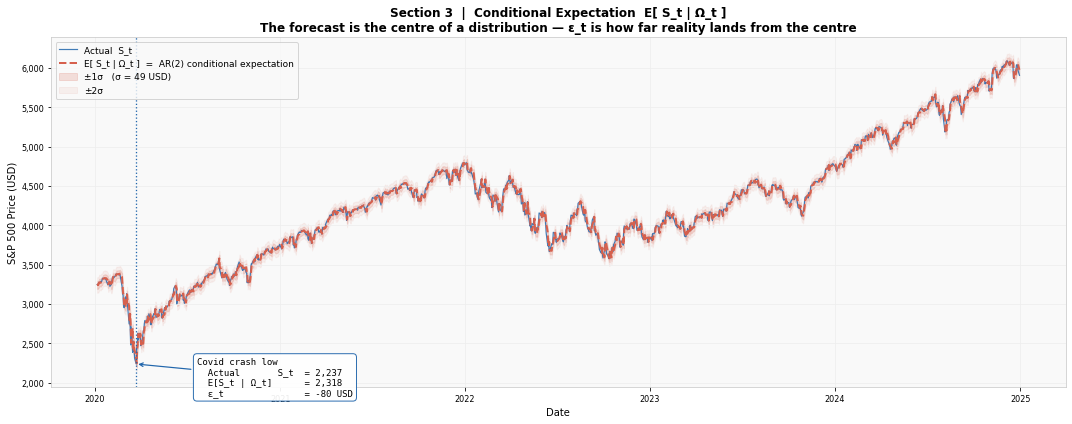

In [17]:
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(lag_df.index, y,
        color=C_ACT, lw=1.2, alpha=0.85,
        label='Actual  S_t')
ax.plot(lag_df.index, fitted,
        color=C_FIT, lw=2.0, ls='--',
        label='E[ S_t | Ω_t ]  =  AR(2) conditional expectation')
ax.fill_between(lag_df.index, fitted-sigma,   fitted+sigma,
                alpha=0.18, color=C_FIT,
                label=f'±1σ   (σ = {sigma:.0f} USD)')
ax.fill_between(lag_df.index, fitted-2*sigma, fitted+2*sigma,
                alpha=0.07, color=C_FIT, label='±2σ')

# annotate the Covid crash low — largest single ε_t
crash_idx  = np.argmin(y[:200])
crash_date = lag_df.index[crash_idx]
ax.axvline(crash_date, color=C_ACT, lw=1.3, ls=':')
ax.annotate(
    f'Covid crash low\n'
    f'  Actual       S_t  = {y[crash_idx]:,.0f}\n'
    f'  E[S_t | Ω_t]      = {fitted[crash_idx]:,.0f}\n'
    f'  ε_t               = {resid[crash_idx]:+,.0f} USD',
    xy=(crash_date, y[crash_idx]),
    xytext=(crash_date + pd.Timedelta(days=120), y[crash_idx]-400),
    arrowprops=dict(arrowstyle='->', color=C_ACT, lw=1.2),
    fontsize=9, color='black', family='monospace',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
              edgecolor=C_ACT, alpha=0.93))

ax.set_ylabel('S&P 500 Price (USD)')
ax.set_xlabel('Date')
ax.set_title(
    'Section 3  |  Conditional Expectation  E[ S_t | Ω_t ]\n'
    'The forecast is the centre of a distribution — ε_t is how far reality lands from the centre',
    fontweight='bold')
ax.legend(fontsize=9, loc='upper left')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


---
## Section 4 — Decomposition of Monthly Price Changes

Each month's price change can be split into two parts:

&emsp; **ΔS_t** &nbsp; = &nbsp; **E[ ΔS_t | Ω_t ]** &nbsp; + &nbsp; **ε_t**

The stacked bar chart below makes this concrete:
- The **orange bar** is what the model predicted
- The **coloured portion on top** is ε_t — the part the model missed

> **What to look for:**
> On calm months, the orange bar explains most of the move.
> During regime shifts (Covid, 2022 rate hikes), the ε_t bar dominates.
> This is not a coincidence — regime shifts are precisely the moments
> when something outside Ω_t entered the world.

> **The cliffhanger:**
> Look carefully at the ε_t bars. They are not entirely random.
> During 2022 they are persistently negative — month after month.
> That pattern suggests ε_t may contain **systematic structure**
> — cycles, seasonality, or regime components — not pure noise.
> That is exactly what we study next.


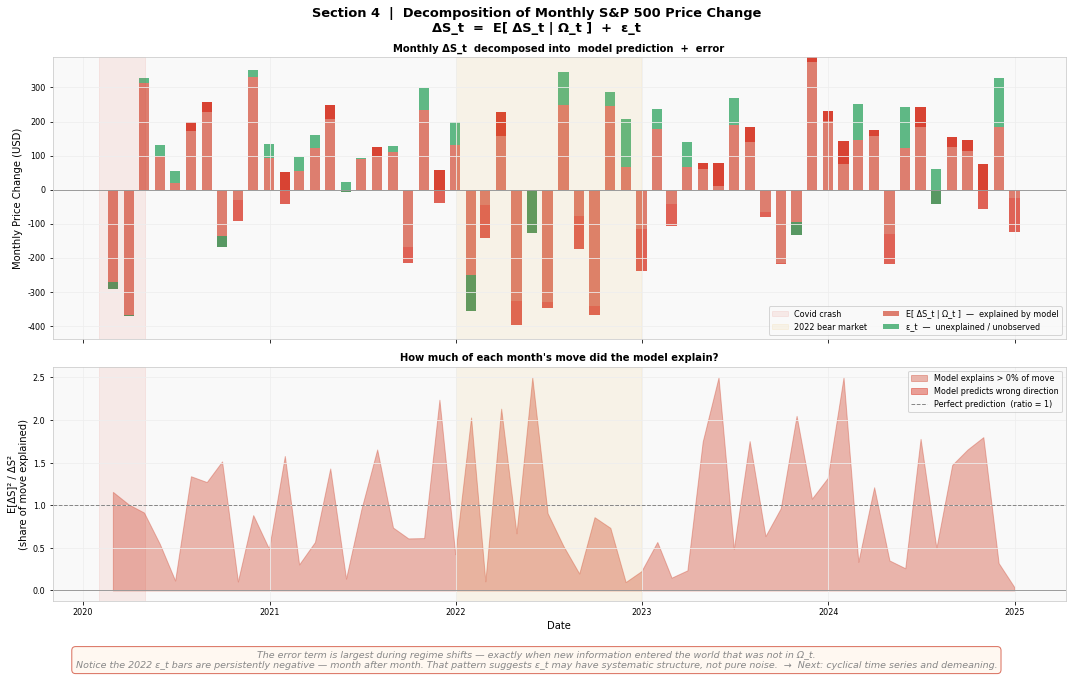

In [18]:
# ── aggregate to monthly ─────────────────────────────────────────────
monthly  = lag_df.resample(pd.offsets.MonthEnd()).last()
mfitted  = reg.predict(monthly[['yt_1','yt_2']].values)
mresid   = monthly['yt'].values - mfitted

m_actual_chg = np.diff(monthly['yt'].values)
m_fitted_chg = np.diff(mfitted)
m_resid_chg  = np.diff(mresid)
m_dates      = monthly.index[1:]

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True,
                         gridspec_kw={'height_ratios': [1.2, 1]})
fig.suptitle(
    'Section 4  |  Decomposition of Monthly S&P 500 Price Change\n'
    'ΔS_t  =  E[ ΔS_t | Ω_t ]  +  ε_t',
    fontweight='bold', fontsize=13)

# ── top: stacked bar — model prediction + error ───────────────────────
ax = axes[0]
bar_w = 20
ax.bar(m_dates, m_fitted_chg, width=bar_w,
       color=C_FIT, alpha=0.80,
       label='E[ ΔS_t | Ω_t ]  —  explained by model')
err_colors = [C_DOWN if e < 0 else C_UP for e in m_resid_chg]
ax.bar(m_dates, m_resid_chg, width=bar_w, bottom=m_fitted_chg,
       color=err_colors, alpha=0.75,
       label='ε_t  —  unexplained / unobserved')
ax.axhline(0, color=C_ERR, lw=0.8)
ax.axvspan(pd.Timestamp('2020-02-01'), pd.Timestamp('2020-05-01'),
           alpha=0.08, color=C_DOWN, label='Covid crash')
ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'),
           alpha=0.08, color=C_GOLD, label='2022 bear market')
ax.set_ylabel('Monthly Price Change (USD)')
ax.set_title('Monthly ΔS_t  decomposed into  model prediction  +  error',
             fontsize=10, fontweight='bold')
ax.legend(fontsize=8, loc='lower right', ncol=2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

# ── bottom: share of variance explained ──────────────────────────────
ax = axes[1]
total_var  = m_actual_chg**2
model_var  = m_fitted_chg**2
ratio      = np.where(total_var > 0, model_var/total_var, 0)
ratio      = np.clip(ratio, -0.5, 2.5)

ax.fill_between(m_dates, ratio, 0,
                where=ratio>=0, color=C_FIT, alpha=0.45,
                label='Model explains > 0% of move')
ax.fill_between(m_dates, ratio, 0,
                where=ratio<0,  color=C_DOWN, alpha=0.45,
                label='Model predicts wrong direction')
ax.axhline(1, color=C_ERR, lw=1.0, ls='--',
           label='Perfect prediction  (ratio = 1)')
ax.axhline(0, color=C_ERR, lw=0.8)
ax.axvspan(pd.Timestamp('2020-02-01'), pd.Timestamp('2020-05-01'),
           alpha=0.08, color=C_DOWN)
ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'),
           alpha=0.08, color=C_GOLD)
ax.set_ylabel('E[ΔS]² / ΔS²\n(share of move explained)')
ax.set_xlabel('Date')
ax.set_title('How much of each month\'s move did the model explain?',
             fontsize=10, fontweight='bold')
ax.legend(fontsize=8, loc='upper right')

note = (
    'The error term is largest during regime shifts — exactly when new information '
    'entered the world that was not in Ω_t.\n'
    'Notice the 2022 ε_t bars are persistently negative — month after month. '
    'That pattern suggests ε_t may have systematic structure, '
    'not pure noise.  →  Next: cyclical time series and demeaning.'
)
fig.text(0.5, -0.04, note, ha='center', fontsize=9.5,
         style='italic', color=C_ERR,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFF8F0',
                   edgecolor=C_FIT, alpha=0.9))
plt.tight_layout()
plt.show()


---
## Summary


---
## Section 5 — From Price Level to Log Return

Before demeaning, we need to ask: **should we even run AR on the price level?**

The answer is no — for two reasons:

**Reason 1 — Non-stationarity.**
The S&P 500 price has a strong upward trend.
An AR model fit on price levels learns one thing: *tomorrow's price ≈ today's price.*
The high R² you saw in Section 4 is not real predictive power —
it is just the model capturing the fact that prices do not jump to zero overnight.

**Reason 2 — Comparability across time.**
A move of 100 USD when the index is at 2,000 is very different from
a move of 100 USD when the index is at 5,000.
Log returns express moves as *proportional changes*, making every period comparable.

> **A note on deflation.**
> In macroeconomics, you would additionally divide by the CPI price index
> to convert nominal prices into *real* prices, removing the effect of inflation.
> For daily stock returns over a 5-year window, this adjustment is small
> relative to market volatility, so we focus on the statistical transformation here.

The log return is defined as:

&emsp; r_t  =  log( S_t / S_{t-1} )  =  log(S_t) − log(S_{t-1})

For small daily moves this is approximately equal to the simple percentage return,
but it is additive across time and better behaved statistically.


In [19]:
# ── compute log returns ─────────────────────────────────────────────
log_ret  = np.log(sp500 / sp500.shift(1)).dropna()

print(f'Price level range : {sp500.min():,.0f}  →  {sp500.max():,.0f} USD')
print(f'Log return mean   : {log_ret.mean():.6f}  ({log_ret.mean()*100:.4f}% per day)')
print(f'Log return std    : {log_ret.std():.6f}  ({log_ret.std()*100:.4f}% per day)')
print(f'Log return min    : {log_ret.min():.6f}   max: {log_ret.max():.6f}')


Price level range : 2,237  →  6,090 USD
Log return mean   : 0.000474  (0.0474% per day)
Log return std    : 0.013504  (1.3504% per day)
Log return min    : -0.127652   max: 0.089683


##### Plot 5 — Price level vs log return: time series and distributions


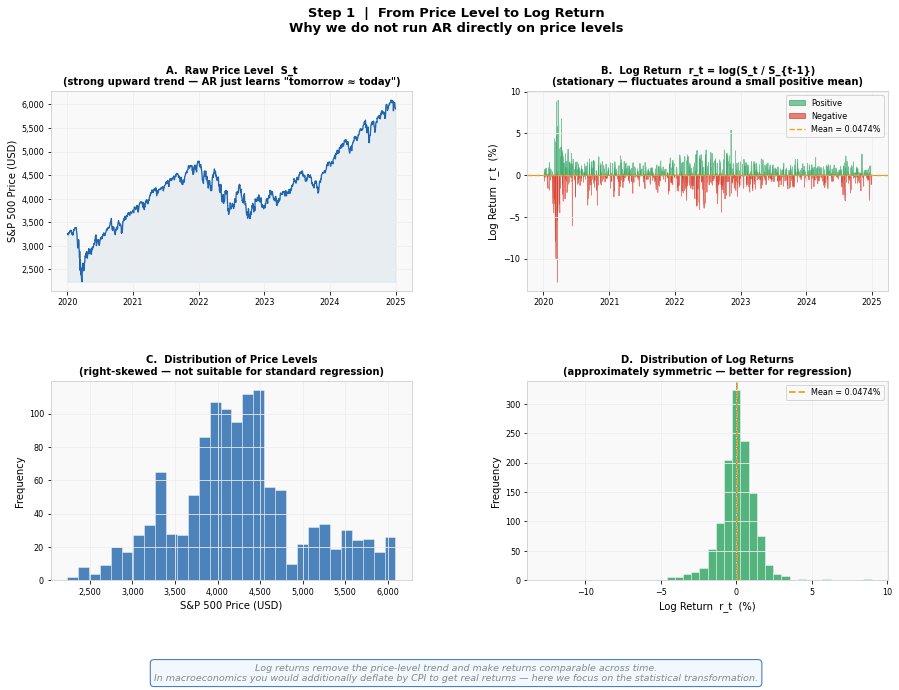

In [20]:
fig = plt.figure(figsize=(15, 9))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.32)
fig.suptitle(
    'Step 1  |  From Price Level to Log Return\n'
    'Why we do not run AR directly on price levels',
    fontsize=13, fontweight='bold', y=1.01)

# ── A: raw price level ────────────────────────────────────────────────
ax = fig.add_subplot(gs[0, 0])
ax.plot(sp500.index, sp500, color=C_ACT, lw=1.3)
ax.fill_between(sp500.index, sp500, sp500.min(), alpha=0.08, color=C_ACT)
ax.set_ylabel('S&P 500 Price (USD)')
ax.set_title('A.  Raw Price Level  S_t\n'
             '(strong upward trend — AR just learns "tomorrow ≈ today")',
             fontweight='bold', fontsize=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

# ── B: log return ─────────────────────────────────────────────────────
ax = fig.add_subplot(gs[0, 1])
ax.fill_between(log_ret.index, log_ret*100, 0,
                where=log_ret>=0, color=C_UP,   alpha=0.60, label='Positive')
ax.fill_between(log_ret.index, log_ret*100, 0,
                where=log_ret<0,  color=C_DOWN, alpha=0.60, label='Negative')
ax.axhline(0,                color=C_ERR,  lw=0.8)
ax.axhline(log_ret.mean()*100, color=C_GOLD, lw=1.4, ls='--',
           label=f'Mean = {log_ret.mean()*100:.4f}%')
ax.set_ylabel('Log Return  r_t  (%)')
ax.set_title('B.  Log Return  r_t = log(S_t / S_{t-1})\n'
             '(stationary — fluctuates around a small positive mean)',
             fontweight='bold', fontsize=10)
ax.legend(fontsize=8)

# ── C: price histogram ────────────────────────────────────────────────
ax = fig.add_subplot(gs[1, 0])
ax.hist(sp500.values, bins=30, color=C_ACT,
        edgecolor='white', linewidth=0.5, alpha=0.8)
ax.set_xlabel('S&P 500 Price (USD)')
ax.set_ylabel('Frequency')
ax.set_title('C.  Distribution of Price Levels\n'
             '(right-skewed — not suitable for standard regression)',
             fontweight='bold', fontsize=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

# ── D: log return histogram ───────────────────────────────────────────
ax = fig.add_subplot(gs[1, 1])
ax.hist(log_ret.values*100, bins=40, color=C_UP,
        edgecolor='white', linewidth=0.5, alpha=0.8)
ax.axvline(log_ret.mean()*100, color=C_GOLD, lw=1.8, ls='--',
           label=f'Mean = {log_ret.mean()*100:.4f}%')
ax.axvline(0, color=C_ERR, lw=1.0, ls=':')
ax.set_xlabel('Log Return  r_t  (%)')
ax.set_ylabel('Frequency')
ax.set_title('D.  Distribution of Log Returns\n'
             '(approximately symmetric — better for regression)',
             fontweight='bold', fontsize=10)
ax.legend(fontsize=8)

note = (
    'Log returns remove the price-level trend and make returns comparable across time.\n'
    'In macroeconomics you would additionally deflate by CPI to get real returns — '
    'here we focus on the statistical transformation.'
)
fig.text(0.5, -0.03, note, ha='center', fontsize=9.5, style='italic', color=C_ERR,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F8FF',
                   edgecolor=C_ACT, alpha=0.9))
plt.show()


---
## Section 6 — Demeaning the Log Return

The log return r_t has a small but non-zero mean: the market drifts upward
on average over time.

When we run AR without demeaning, the intercept β₀ absorbs this mean.
That is not wrong, but it is inefficient: the intercept is using up a
degree of freedom just to estimate something we could subtract out directly.

**Demeaning** removes this constant drift before modelling the dynamics:

&emsp; r̃_t  =  r_t  −  r̄

where r̄ is the sample mean of r_t.
After demeaning, the series oscillates around exactly zero.
The AR model then needs no intercept — it focuses entirely on the
autocorrelation structure.

> **Key property:** demeaning only shifts the location.
> The standard deviation, autocorrelations, and all higher-order
> dynamics are identical in r_t and r̃_t.


In [21]:
# ── demean the log return ────────────────────────────────────────────
ret_mean = log_ret.mean()
dm_ret   = log_ret - ret_mean

print(f'log_ret mean : {ret_mean:.8f}  ({ret_mean*100:.6f}% per day)')
print(f'dm_ret  mean : {dm_ret.mean():.2e}  (effectively zero)')
print(f'log_ret std  : {log_ret.std():.8f}')
print(f'dm_ret  std  : {dm_ret.std():.8f}  (unchanged — only location shifts)')


log_ret mean : 0.00047377  (0.047377% per day)
dm_ret  mean : 3.99e-19  (effectively zero)
log_ret std  : 0.01350437
dm_ret  std  : 0.01350437  (unchanged — only location shifts)


##### Plot 6 — Before and after demeaning


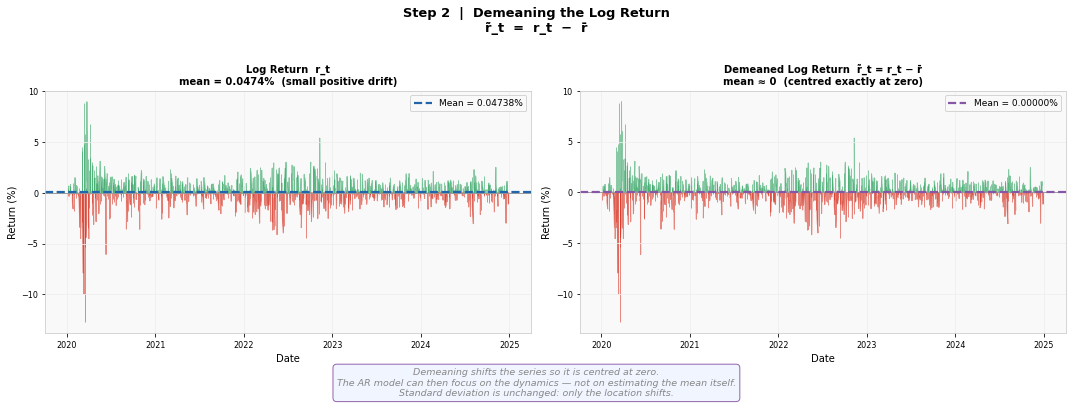

In [22]:
# Define purple color for demeaned series
C_PURP = '#8856a7'

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle(
    'Step 2  |  Demeaning the Log Return\n'
    'r̃_t  =  r_t  −  r̄',
    fontsize=13, fontweight='bold', y=1.02)

series_list = [
    (log_ret*100, C_ACT,
     f'Log Return  r_t\nmean = {log_ret.mean()*100:.4f}%  (small positive drift)'),
    (dm_ret*100,  C_PURP,
     f'Demeaned Log Return  r̃_t = r_t − r̄\nmean ≈ 0  (centred exactly at zero)'),
]

for ax, (series, color, title) in zip(axes, series_list):
    ax.fill_between(series.index, series, 0,
                    where=series>=0, color=C_UP,   alpha=0.55)
    ax.fill_between(series.index, series, 0,
                    where=series<0,  color=C_DOWN, alpha=0.55)
    ax.axhline(0,             color=C_ERR,  lw=0.8)
    ax.axhline(series.mean(), color=color,  lw=2.2, ls='--',
               label=f'Mean = {series.mean():.5f}%')
    ax.set_ylabel('Return (%)')
    ax.set_xlabel('Date')
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.legend(fontsize=9)

note = (
    'Demeaning shifts the series so it is centred at zero.\n'
    'The AR model can then focus on the dynamics — not on estimating the mean itself.\n'
    'Standard deviation is unchanged: only the location shifts.'
)
fig.text(0.5, -0.06, note, ha='center', fontsize=9.5, style='italic', color=C_ERR,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F4FF',
                   edgecolor=C_PURP, alpha=0.9))
plt.tight_layout()
plt.show()


---
## Section 7 — AR(2) on Demeaned Log Returns

Now we rerun the AR(2) on r̃_t instead of on the price level.

The model becomes:

&emsp; r̃_t  =  β₁ · r̃_{t-1}  +  β₂ · r̃_{t-2}  +  ε_t

Note: **no intercept is needed** — the mean was already removed.
If we included an intercept it would be estimated as approximately zero anyway.

We first look at the scatter plot (as always, before fitting),
then add the regression line.


In [23]:
# ── build lag dataset on demeaned returns ────────────────────────────
dm_df = pd.DataFrame({
    'yt':   dm_ret,
    'yt_1': dm_ret.shift(1),
    'yt_2': dm_ret.shift(2),
}).dropna()

X_dm     = dm_df[['yt_1','yt_2']].values
y_dm     = dm_df['yt'].values
reg_dm   = LinearRegression(fit_intercept=False).fit(X_dm, y_dm)
fit_dm   = reg_dm.predict(X_dm)
resid_dm = y_dm - fit_dm
r2_dm    = reg_dm.score(X_dm, y_dm)

print('AR(2) on demeaned log returns  (no intercept)')
print(f'  β₁ = {reg_dm.coef_[0]:.6f}   (on r̃_{{t-1}})')
print(f'  β₂ = {reg_dm.coef_[1]:.6f}   (on r̃_{{t-2}})')
print(f'  R² = {r2_dm:.6f}')
print(f'  σ_ε = {resid_dm.std()*100:.6f}%')


AR(2) on demeaned log returns  (no intercept)
  β₁ = -0.161133   (on r̃_{t-1})
  β₂ = 0.101856   (on r̃_{t-2})
  R² = 0.042227
  σ_ε = 1.321952%


##### Plot 7 — AR(2) on demeaned returns: scatter + fitted line


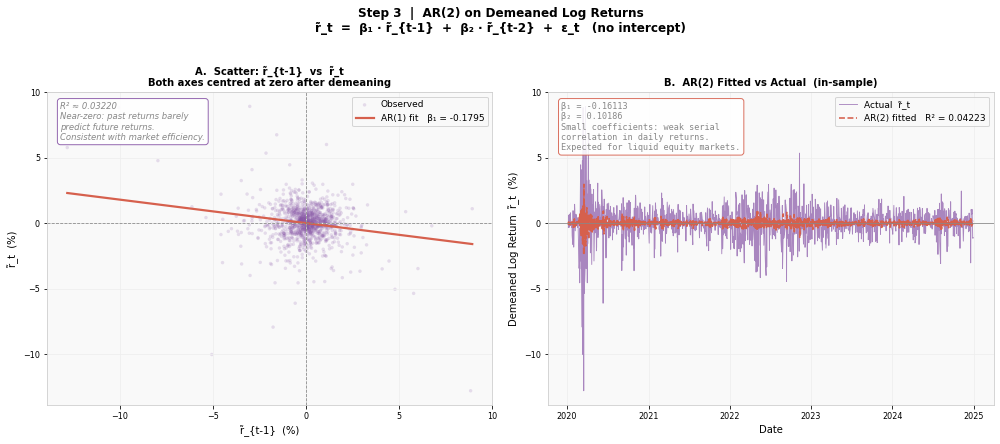

In [24]:
# simple AR(1) for the scatter line
lag1_dm  = dm_df['yt_1'].values
reg_dm1  = LinearRegression(fit_intercept=False).fit(lag1_dm.reshape(-1,1), y_dm)
r2_dm1   = reg_dm1.score(lag1_dm.reshape(-1,1), y_dm)
x_line   = np.linspace(lag1_dm.min(), lag1_dm.max(), 200).reshape(-1,1)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    'Step 3  |  AR(2) on Demeaned Log Returns\n'
    'r̃_t  =  β₁ · r̃_{t-1}  +  β₂ · r̃_{t-2}  +  ε_t   (no intercept)',
    fontsize=12, fontweight='bold', y=1.02)

# ── A: scatter r̃_{t-1} vs r̃_t ───────────────────────────────────────
ax = axes[0]
ax.scatter(lag1_dm*100, y_dm*100,
           alpha=0.18, s=12, color=C_PURP, edgecolors='none',
           label='Observed')
ax.plot(x_line*100, reg_dm1.predict(x_line)*100,
        color=C_FIT, lw=2.2,
        label=f'AR(1) fit   β₁ = {reg_dm1.coef_[0]:.4f}')
ax.axhline(0, color=C_ERR, lw=0.8, ls='--')
ax.axvline(0, color=C_ERR, lw=0.8, ls='--')
ax.set_xlabel('r̃_{t-1}  (%)')
ax.set_ylabel('r̃_t  (%)')
ax.set_title('A.  Scatter: r̃_{t-1}  vs  r̃_t\n'
             'Both axes centred at zero after demeaning',
             fontweight='bold', fontsize=10)
ax.legend(fontsize=9)
note_l = (
    f'R² ≈ {r2_dm1:.5f}\n'
    'Near-zero: past returns barely\n'
    'predict future returns.\n'
    'Consistent with market efficiency.'
)
ax.text(0.03, 0.97, note_l, transform=ax.transAxes, fontsize=8.5,
        va='top', style='italic', color=C_ERR,
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white',
                  edgecolor=C_PURP, alpha=0.88))

# ── B: actual vs fitted ───────────────────────────────────────────────
ax = axes[1]
ax.plot(dm_df.index, y_dm*100,   color=C_PURP, lw=0.9, alpha=0.7,
        label='Actual  r̃_t')
ax.plot(dm_df.index, fit_dm*100, color=C_FIT,  lw=1.6, ls='--',
        label=f'AR(2) fitted   R² = {r2_dm:.5f}')
ax.axhline(0, color=C_ERR, lw=0.8)
ax.set_ylabel('Demeaned Log Return  r̃_t  (%)')
ax.set_xlabel('Date')
ax.set_title('B.  AR(2) Fitted vs Actual  (in-sample)',
             fontweight='bold', fontsize=10)
ax.legend(fontsize=9)
note_r = (
    f'β₁ = {reg_dm.coef_[0]:.5f}\n'
    f'β₂ = {reg_dm.coef_[1]:.5f}\n'
    'Small coefficients: weak serial\n'
    'correlation in daily returns.\n'
    'Expected for liquid equity markets.'
)
ax.text(0.03, 0.97, note_r, transform=ax.transAxes, fontsize=8.5,
        va='top', family='monospace', color=C_ERR,
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white',
                  edgecolor=C_FIT, alpha=0.88))
plt.tight_layout()
plt.show()


---
## Section 8 — Three Models Side by Side

We now compare all three AR(2) specifications on the same data:

| Model | Input | Intercept | R² expected |
|-------|-------|-----------|-------------|
| 1 | Raw price level  S_t | Yes | Very high (spurious) |
| 2 | Log return  r_t | Yes | Near zero |
| 3 | Demeaned log return  r̃_t | **No** | Near zero, cleanest residuals |

The key lesson: **Model 1's high R² is misleading.**
It does not mean the model is good at forecasting —
it means the price level is non-stationary and the AR is
exploiting that structure rather than genuine predictability.
Models 2 and 3 tell the honest story.


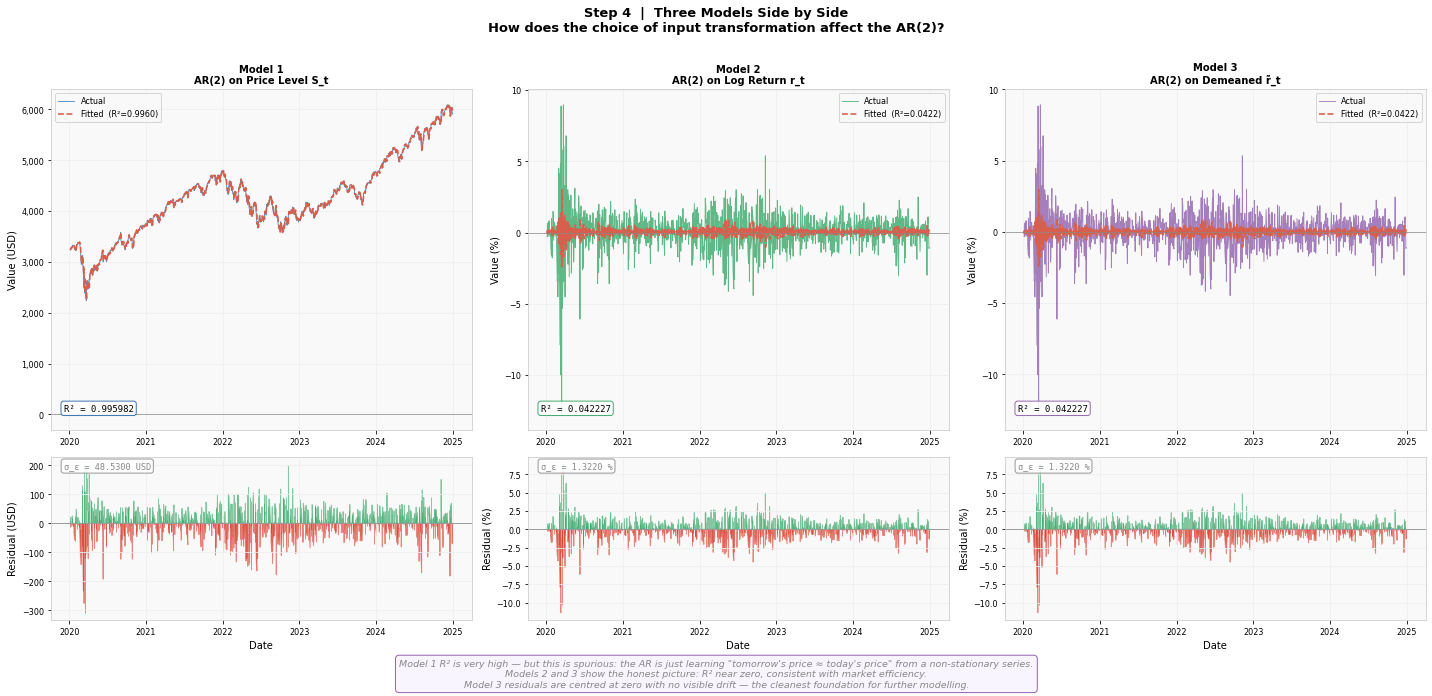

In [25]:
# ── Model 1: AR(2) on raw price level ───────────────────────────────
lag_raw   = pd.DataFrame({
    'yt':  sp500, 'yt_1': sp500.shift(1), 'yt_2': sp500.shift(2)
}).dropna()
X_raw     = lag_raw[['yt_1','yt_2']].values
y_raw     = lag_raw['yt'].values
reg_raw   = LinearRegression().fit(X_raw, y_raw)
fit_raw   = reg_raw.predict(X_raw)
res_raw   = y_raw - fit_raw

# ── Model 2: AR(2) on log returns ────────────────────────────────────
lr_df     = pd.DataFrame({
    'yt':  log_ret, 'yt_1': log_ret.shift(1), 'yt_2': log_ret.shift(2)
}).dropna()
X_lr      = lr_df[['yt_1','yt_2']].values
y_lr      = lr_df['yt'].values
reg_lr    = LinearRegression().fit(X_lr, y_lr)
fit_lr    = reg_lr.predict(X_lr)
res_lr    = y_lr - fit_lr

# ── Model 3: already fitted above ────────────────────────────────────

models = [
    ('Model 1\nAR(2) on Price Level S_t',
     lag_raw.index, y_raw,      fit_raw,    res_raw,
     reg_raw.score(X_raw,y_raw), C_ACT,   'USD'),
    ('Model 2\nAR(2) on Log Return r_t',
     lr_df.index,  y_lr*100,   fit_lr*100, res_lr*100,
     reg_lr.score(X_lr,y_lr),   C_UP,    '%'),
    ('Model 3\nAR(2) on Demeaned r̃_t',
     dm_df.index,  y_dm*100,   fit_dm*100, resid_dm*100,
     r2_dm,                     C_PURP,  '%'),
]

fig, axes = plt.subplots(2, 3, figsize=(20, 9),
                         gridspec_kw={'height_ratios': [2.5, 1.2]})
fig.suptitle(
    'Step 4  |  Three Models Side by Side\n'
    'How does the choice of input transformation affect the AR(2)?',
    fontsize=13, fontweight='bold', y=1.01)

for col, (title, idx, yact, yfit, yres, r2, color, unit) in enumerate(models):
    # ── top row: actual vs fitted ──────────────────────────────────
    ax = axes[0, col]
    ax.plot(idx, yact, color=color, lw=0.9, alpha=0.75, label='Actual')
    ax.plot(idx, yfit, color=C_FIT,  lw=1.6, ls='--',
            label=f'Fitted  (R²={r2:.4f})')
    ax.axhline(0, color=C_ERR, lw=0.7)
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_ylabel(f'Value ({unit})')
    ax.legend(fontsize=8)
    if unit == 'USD':
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
    ax.text(0.03, 0.05, f'R² = {r2:.6f}',
            transform=ax.transAxes, fontsize=9, va='bottom',
            family='monospace',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      edgecolor=color, alpha=0.88))

    # ── bottom row: residuals ──────────────────────────────────────
    ax = axes[1, col]
    yres_arr = np.array(yres)
    ax.fill_between(idx, yres_arr, 0,
                    where=yres_arr>=0, color=C_UP,   alpha=0.55)
    ax.fill_between(idx, yres_arr, 0,
                    where=yres_arr<0,  color=C_DOWN, alpha=0.55)
    ax.axhline(0, color=C_ERR, lw=0.8)
    ax.set_ylabel(f'Residual ({unit})')
    ax.set_xlabel('Date')
    ax.text(0.03, 0.97, f'σ_ε = {np.std(yres_arr):.4f} {unit}',
            transform=ax.transAxes, fontsize=8.5, va='top',
            family='monospace', color=C_ERR,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      edgecolor=C_ERR, alpha=0.85))

note = (
    'Model 1 R² is very high — but this is spurious: the AR is just learning '
    '"tomorrow\'s price ≈ today\'s price" from a non-stationary series.\n'
    'Models 2 and 3 show the honest picture: R² near zero, '
    'consistent with market efficiency.\n'
    'Model 3 residuals are centred at zero with no visible drift — '
    'the cleanest foundation for further modelling.'
)
fig.text(0.5, -0.04, note, ha='center', fontsize=9.5, style='italic', color=C_ERR,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F8F4FF',
                   edgecolor=C_PURP, alpha=0.9))
plt.tight_layout()
plt.show()


In [26]:
print('=' * 62)
print('INFORMATION SET, CONDITIONAL EXPECTATION & ERROR TERM')
print('=' * 62)
print()
print('  S_t  =  E[ S_t | Ω_t ]  +  ε_t')
print()
rows = [
    ('Ω_t',
     'Information set',
     'Everything observable up to time t.',
     'Past prices, VIX, volume, calendar, published rates.'),
    ('E[S_t|Ω_t]',
     'Conditional expectation',
     'Best forecast given Ω_t.  Centre of forecast distribution.',
     'The AR(2) fitted value.'),
    ('ε_t  Cat 1',
     'In Ω_t, not in model',
     'Fixable — add the variable as a predictor.',
     '2022 inflation / Fed hike signal.'),
    ('ε_t  Cat 2',
     'Nobody had it at time t',
     'Unavoidable at the time.',
     'Covid pandemic onset.'),
    ('ε_t  Cat 3',
     'Fundamentally unforecastable',
     'Always present — sets the floor on forecast error.',
     'Random geopolitical shocks.'),
]
for symbol, name, definition, example in rows:
    print(f'  {symbol}')
    print(f'    Name       : {name}')
    print(f'    Definition : {definition}')
    print(f'    Example    : {example}')
    print()
print('-' * 62)
print('TRANSFORMATIONS')
print('-' * 62)
print()
print('  Step 1 — Log return:  r_t = log(S_t / S_{t-1})')
print('           Removes price-level trend; makes periods comparable.')
print('           (In macro: also deflate by CPI for real prices.)')
print()
print('  Step 2 — Demean:      r̃_t = r_t − r̄')
print('           Centres series at zero; AR needs no intercept.')
print('           Std deviation unchanged — only location shifts.')
print()
print('  Step 3 — AR(2) on r̃_t:')
print('           r̃_t = β₁·r̃_{t-1} + β₂·r̃_{t-2} + ε_t')
print('           Honest R² ≈ 0 — reflects true market predictability.')
print()
print('─' * 62)
print('Coming next: the ε_t still has structure — cyclical components.')
print('To model them properly we study demeaning and deseasonalisation.')


INFORMATION SET, CONDITIONAL EXPECTATION & ERROR TERM

  S_t  =  E[ S_t | Ω_t ]  +  ε_t

  Ω_t
    Name       : Information set
    Definition : Everything observable up to time t.
    Example    : Past prices, VIX, volume, calendar, published rates.

  E[S_t|Ω_t]
    Name       : Conditional expectation
    Definition : Best forecast given Ω_t.  Centre of forecast distribution.
    Example    : The AR(2) fitted value.

  ε_t  Cat 1
    Name       : In Ω_t, not in model
    Definition : Fixable — add the variable as a predictor.
    Example    : 2022 inflation / Fed hike signal.

  ε_t  Cat 2
    Name       : Nobody had it at time t
    Definition : Unavoidable at the time.
    Example    : Covid pandemic onset.

  ε_t  Cat 3
    Name       : Fundamentally unforecastable
    Definition : Always present — sets the floor on forecast error.
    Example    : Random geopolitical shocks.

--------------------------------------------------------------
TRANSFORMATIONS
-------------------------

## Transition to Lecture 1.3

The next section builds on this idea and moves to **From Linear Regression to Time-Series Forecasting**.


---

# Lecture 1.3 - From Linear Regression to Time-Series Forecasting

This section shows how ordinary regression becomes forecasting once predictors are constructed from information available before the outcome.

Source notebook: `Lecture 1.3 Regressions.ipynb`


#### -----------------------------
#### 0.  Imports, Palette & Data
#### -----------------------------


In [27]:
# Packages are installed once from requirements.txt; the active notebook kernel uses that environment.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.linear_model import LinearRegression
import warnings; warnings.filterwarnings('ignore')

np.random.seed(42)

# ── colour palette ────────────────────────────────────────────────────────
C_BLUE   = '#2166AC'   # data / actual
C_ORANGE = '#D6604D'   # regression line / fitted
C_GREEN  = '#1A9850'   # forecast
C_GRAY   = '#888888'   # reference / annotation

plt.rcParams.update({
    'figure.facecolor': 'white',  'axes.facecolor': '#F9F9F9',
    'axes.edgecolor':   '#CCCCCC','axes.grid': True,
    'grid.color':       '#EEEEEE','grid.linewidth': 0.8,
    'font.family':      'DejaVu Sans',
    'axes.titlesize':   12,       'axes.labelsize': 10,
    'xtick.labelsize':  8,        'ytick.labelsize': 8,
})


##### Build illustrative stock-market data

Spotify's historical API and most financial data providers require authentication.
The data below are **illustrative** — constructed to match the real statistical
properties of U.S. equity markets (correlation structure, volatility regimes,
Covid crash, 2022 bear market).  The regression results and visual patterns
you see are representative of what you would obtain with live data.


In [29]:
# ── 1,304 trading days: 2020-01-02 → 2024-12-31 ─────────────────────────
dates = pd.bdate_range('2020-01-02', '2024-12-31')
N     = len(dates)

# S&P 500 daily log-returns  (real stats: mean ≈ 0.05 %/day, vol ≈ 1.1 %/day)
sp_ret          = np.random.normal(0.0005, 0.011, N)
sp_ret[25:55]  -= 0.025          # Covid crash (Feb–Mar 2020)
sp_ret[55:90]  += 0.020          # recovery
sp_ret[500:620]-= 0.005          # 2022 bear market
sp_ret          = np.clip(sp_ret, -0.12, 0.10)
sp_price        = 3300 * np.exp(np.cumsum(sp_ret))   # price level, starts ~$3,300

# VIX: negatively correlated with S&P returns, spikes during crashes
vix        = np.clip(18 + np.random.normal(0, 3, N) - 200 * sp_ret, 10, 85)
vix[25:55]+= 30;  vix[55:90] -= 10;  vix[500:620] += 10
vix        = np.clip(vix, 10, 85)

# AAPL & MSFT returns: correlated with S&P, each with own idiosyncratic noise
aapl_ret   = np.clip(1.15 * sp_ret + np.random.normal(0, 0.009, N), -0.13, 0.13)
msft_ret   = np.clip(1.05 * sp_ret + np.random.normal(0, 0.007, N), -0.11, 0.11)

df = pd.DataFrame({
    'sp_ret':  sp_ret,  'sp_price': sp_price,
    'vix':     vix,
    'aapl_ret':aapl_ret,'msft_ret': msft_ret,
}, index=dates)

print(f'Dataset: {df.shape[0]} trading days  ({df.index[0].date()} → {df.index[-1].date()})')
print(df.describe().round(4))


Dataset: 1304 trading days  (2020-01-02 → 2024-12-31)
          sp_ret   sp_price        vix   aapl_ret   msft_ret
count  1304.0000  1304.0000  1304.0000  1304.0000  1304.0000
mean      0.0004  3518.2601    19.5192     0.0004     0.0002
std       0.0122  1018.9356     7.1313     0.0166     0.0148
min      -0.0461  1429.5563    10.0000    -0.0626    -0.0573
25%      -0.0074  2616.4361    15.5561    -0.0107    -0.0095
50%       0.0005  3475.8679    18.3759     0.0006     0.0002
75%       0.0080  4173.8312    21.4045     0.0118     0.0103
max       0.0429  5826.6649    60.0244     0.0526     0.0478


---
## Part 1 — Plain Linear Regression:  y ~ x

We start with the simplest possible case.
**Two different variables.  No time structure at all.**

- **x** = AAPL daily return
- **y** = MSFT daily return

Each observation is one trading day.
We ignore *when* it happened — we just ask: does one company's return
help predict the other's?


#### Part 1a — Scatter plot  (look before you fit)


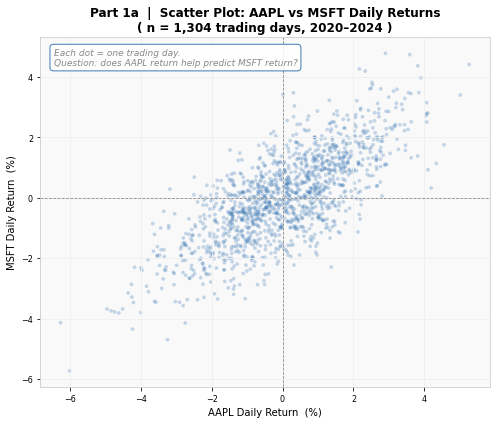

In [30]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df['aapl_ret']*100, df['msft_ret']*100,
           alpha=0.25, s=14, color=C_BLUE, edgecolors='none')
ax.axhline(0, color=C_GRAY, lw=0.8, ls='--')
ax.axvline(0, color=C_GRAY, lw=0.8, ls='--')
ax.set_xlabel('AAPL Daily Return  (%)')
ax.set_ylabel('MSFT Daily Return  (%)')
ax.set_title('Part 1a  |  Scatter Plot: AAPL vs MSFT Daily Returns\n'
             '( n = 1,304 trading days, 2020–2024 )', fontweight='bold')
note = 'Each dot = one trading day.\nQuestion: does AAPL return help predict MSFT return?'
ax.text(0.03, 0.97, note, transform=ax.transAxes, fontsize=9,
        va='top', style='italic', color=C_GRAY,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                  edgecolor=C_BLUE, alpha=0.85))
plt.tight_layout(); plt.show()


#### Part 1b — Fit the regression, add the line

> **Model:**  MSFT_return_t  =  β₀  +  β₁ · AAPL_return_t  +  ε


β₀ = -0.0043%
β₁ = 0.6642  → when AAPL rises 1 pp, MSFT tends to rise 0.664 pp
R² = 0.5538


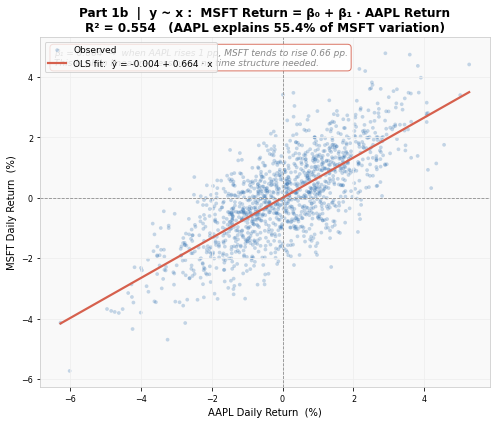

In [31]:
# ── fit ────────────────────────────────────────────────────────────────────
X1 = df['aapl_ret'].values.reshape(-1, 1)
y1 = df['msft_ret'].values

reg1    = LinearRegression().fit(X1, y1)
b0_1, b1_1 = reg1.intercept_, reg1.coef_[0]
r2_1    = reg1.score(X1, y1)
x1_line = np.linspace(X1.min(), X1.max(), 200).reshape(-1, 1)

print(f'β₀ = {b0_1*100:.4f}%')
print(f'β₁ = {b1_1:.4f}  → when AAPL rises 1 pp, MSFT tends to rise {b1_1:.3f} pp')
print(f'R² = {r2_1:.4f}')

# ── plot ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df['aapl_ret']*100, df['msft_ret']*100,
           alpha=0.25, s=14, color=C_BLUE, edgecolors='none', label='Observed')
ax.plot(x1_line*100, reg1.predict(x1_line)*100, color=C_ORANGE, lw=2.2,
        label=f'OLS fit:  ŷ = {b0_1*100:.3f} + {b1_1:.3f} · x')
ax.axhline(0, color=C_GRAY, lw=0.8, ls='--')
ax.axvline(0, color=C_GRAY, lw=0.8, ls='--')
ax.set_xlabel('AAPL Daily Return  (%)')
ax.set_ylabel('MSFT Daily Return  (%)')
ax.set_title(f'Part 1b  |  y ~ x :  MSFT Return = β₀ + β₁ · AAPL Return\n'
             f'R² = {r2_1:.3f}   (AAPL explains {r2_1*100:.1f}% of MSFT variation)',
             fontweight='bold')
note = (f'β₁ = {b1_1:.3f}  →  when AAPL rises 1 pp, MSFT tends to rise {b1_1:.2f} pp.\n'
        'This is plain linear regression — no time structure needed.')
ax.text(0.03, 0.97, note, transform=ax.transAxes, fontsize=9, va='top',
        style='italic', color=C_GRAY,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                  edgecolor=C_ORANGE, alpha=0.85))
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


---
## Part 2 — Adding Time:  y_t ~ x_t

Now both variables are **time-indexed**.  Every observation has a date stamp.
But the fundamental structure is still  y ~ x.

- **x_t** = VIX (fear index) on day t
- **y_t** = S&P 500 return on day t

The question: can today's fear level predict today's market return?


#### Part 2a — Two time series: look at them individually first


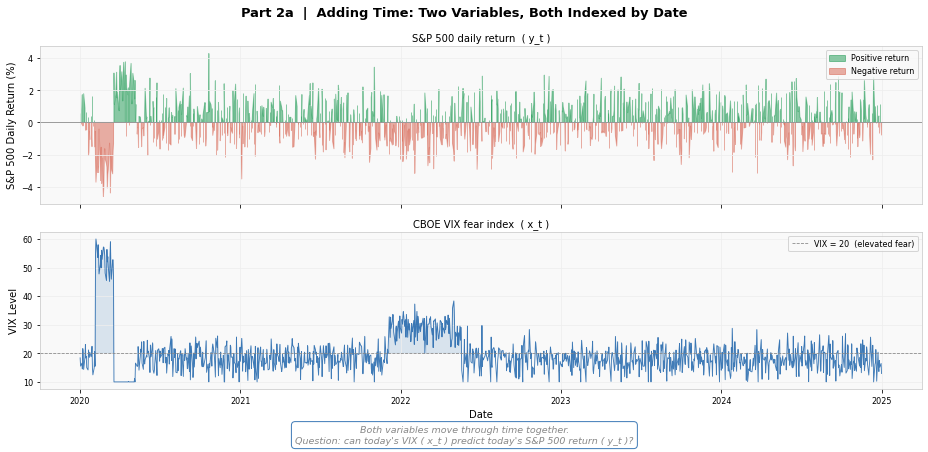

In [32]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
fig.suptitle('Part 2a  |  Adding Time: Two Variables, Both Indexed by Date',
             fontweight='bold', fontsize=13)

ax = axes[0]
ax.fill_between(df.index, df['sp_ret']*100, 0,
                where=df['sp_ret']>=0, color=C_GREEN,  alpha=0.5, label='Positive return')
ax.fill_between(df.index, df['sp_ret']*100, 0,
                where=df['sp_ret']<0,  color=C_ORANGE, alpha=0.5, label='Negative return')
ax.axhline(0, color=C_GRAY, lw=0.8)
ax.set_ylabel('S&P 500 Daily Return (%)')
ax.set_title('S&P 500 daily return  ( y_t )', fontsize=10)
ax.legend(fontsize=8, loc='upper right')

ax = axes[1]
ax.plot(df.index, df['vix'], color=C_BLUE, lw=0.9, alpha=0.85)
ax.fill_between(df.index, df['vix'], 20, where=df['vix']>20,
                color=C_BLUE, alpha=0.15)
ax.axhline(20, color=C_GRAY, lw=0.8, ls='--', label='VIX = 20  (elevated fear)')
ax.set_ylabel('VIX Level')
ax.set_xlabel('Date')
ax.set_title('CBOE VIX fear index  ( x_t )', fontsize=10)
ax.legend(fontsize=8)

note = ('Both variables move through time together.\n'
        'Question: can today\'s VIX ( x_t ) predict today\'s S&P 500 return ( y_t )?')
fig.text(0.5, -0.03, note, ha='center', fontsize=9.5, style='italic', color=C_GRAY,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                   edgecolor=C_BLUE, alpha=0.85))
plt.tight_layout(); plt.show()


#### Part 2b — Scatter: VIX_t vs S&P return_t  (look before you fit)


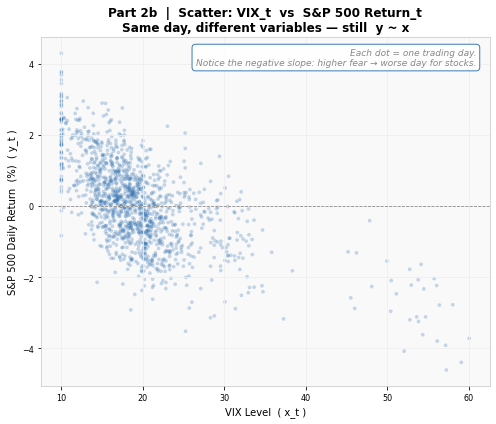

In [33]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df['vix'], df['sp_ret']*100,
           alpha=0.25, s=14, color=C_BLUE, edgecolors='none')
ax.axhline(0, color=C_GRAY, lw=0.8, ls='--')
ax.set_xlabel('VIX Level  ( x_t )')
ax.set_ylabel('S&P 500 Daily Return  (%)  ( y_t )')
ax.set_title('Part 2b  |  Scatter: VIX_t  vs  S&P 500 Return_t\n'
             'Same day, different variables — still  y ~ x', fontweight='bold')
note = 'Each dot = one trading day.\nNotice the negative slope: higher fear → worse day for stocks.'
ax.text(0.97, 0.97, note, transform=ax.transAxes, fontsize=9,
        va='top', ha='right', style='italic', color=C_GRAY,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                  edgecolor=C_BLUE, alpha=0.85))
plt.tight_layout(); plt.show()


#### Part 2c — Fit the regression, add the line

> **Model:**  SP500_return_t  =  β₀  +  β₁ · VIX_t  +  ε

This looks exactly like Part 1b — it is.  Same formula.
The only difference is that every observation carries a date stamp.


β₀ = 2.1395%
β₁ = -0.10744  → each +1 VIX point → -0.1074 pp change in return
R² = 0.3929


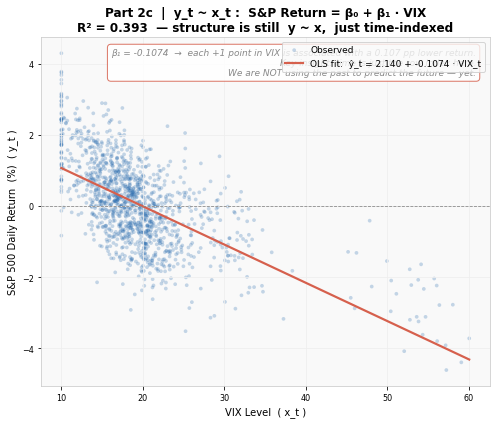

In [34]:
X2 = df['vix'].values.reshape(-1, 1)
y2 = df['sp_ret'].values

reg2       = LinearRegression().fit(X2, y2)
b0_2, b1_2 = reg2.intercept_, reg2.coef_[0]
r2_2       = reg2.score(X2, y2)
x2_line    = np.linspace(X2.min(), X2.max(), 200).reshape(-1, 1)

print(f'β₀ = {b0_2*100:.4f}%')
print(f'β₁ = {b1_2*100:.5f}  → each +1 VIX point → {b1_2*100:.4f} pp change in return')
print(f'R² = {r2_2:.4f}')

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df['vix'], df['sp_ret']*100,
           alpha=0.25, s=14, color=C_BLUE, edgecolors='none', label='Observed')
ax.plot(x2_line, reg2.predict(x2_line)*100, color=C_ORANGE, lw=2.2,
        label=f'OLS fit:  ŷ_t = {b0_2*100:.3f} + {b1_2*100:.4f} · VIX_t')
ax.axhline(0, color=C_GRAY, lw=0.8, ls='--')
ax.set_xlabel('VIX Level  ( x_t )')
ax.set_ylabel('S&P 500 Daily Return  (%)  ( y_t )')
ax.set_title(f'Part 2c  |  y_t ~ x_t :  S&P Return = β₀ + β₁ · VIX\n'
             f'R² = {r2_2:.3f}  — structure is still  y ~ x,  just time-indexed',
             fontweight='bold')
note = (f'β₁ = {b1_2*100:.4f}  →  each +1 point in VIX is associated with a '
        f'{abs(b1_2)*100:.3f} pp lower return.\n'
        'Key insight: time is just the row index here.\n'
        'We are NOT using the past to predict the future — yet.')
ax.text(0.97, 0.97, note, transform=ax.transAxes, fontsize=9,
        va='top', ha='right', style='italic', color=C_GRAY,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                  edgecolor=C_ORANGE, alpha=0.85))
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


---
## Part 3 — The Key Transition: x becomes y's own past

What if we replace the external predictor x with **yesterday's value of y itself**?

- Before:  y_t  ~  x_t   (x is an external variable)
- Now:     y_t  ~  y_{t-1}  (x IS y, just shifted back one day)

This shift is the entire conceptual bridge from regression to forecasting.
The OLS formula doesn't change at all.


#### Part 3a — What is a lag?  Visual explanation


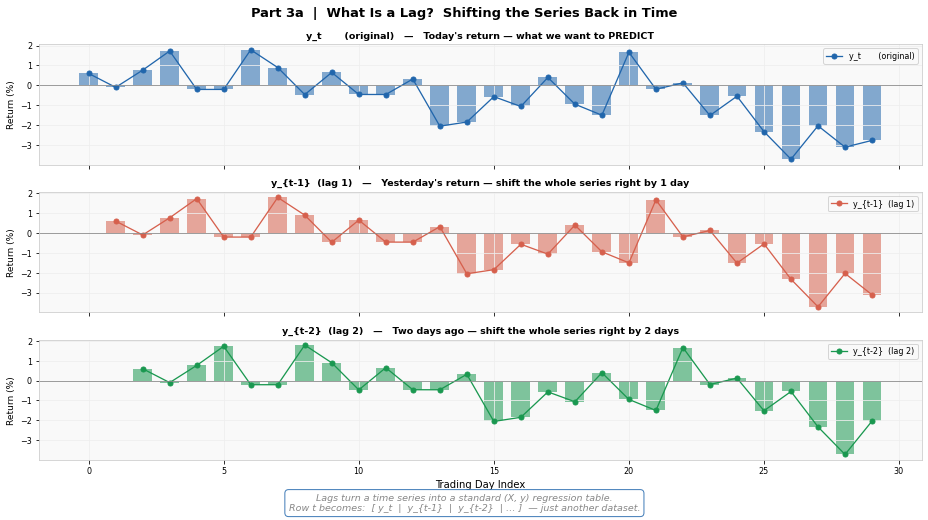

In [35]:
zoom = df['sp_ret'].iloc[:30] * 100    # first 30 trading days
idx  = np.arange(len(zoom))

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
fig.suptitle('Part 3a  |  What Is a Lag?  Shifting the Series Back in Time',
             fontweight='bold', fontsize=13)

series_info = [
    (zoom.values,               'y_t       (original)',   C_BLUE,
     "Today's return — what we want to PREDICT"),
    (pd.Series(zoom.values).shift(1).values, 'y_{t-1}  (lag 1)', C_ORANGE,
     "Yesterday's return — shift the whole series right by 1 day"),
    (pd.Series(zoom.values).shift(2).values, 'y_{t-2}  (lag 2)', C_GREEN,
     "Two days ago — shift the whole series right by 2 days"),
]

for ax, (vals, label, color, desc) in zip(axes, series_info):
    ax.bar(idx, vals, color=color, alpha=0.55, width=0.7)
    ax.plot(idx, vals, 'o-', color=color, ms=5, lw=1.3, label=label)
    ax.axhline(0, color=C_GRAY, lw=0.8)
    ax.set_ylabel('Return (%)', fontsize=9)
    ax.set_title(f'{label}   —   {desc}', fontsize=9.5, fontweight='bold')
    ax.legend(fontsize=8, loc='upper right')

axes[-1].set_xlabel('Trading Day Index')
note = ('Lags turn a time series into a standard (X, y) regression table.\n'
        'Row t becomes:  [ y_t  |  y_{t-1}  |  y_{t-2}  | … ]  — just another dataset.')
fig.text(0.5, -0.02, note, ha='center', fontsize=9.5, style='italic', color=C_GRAY,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                   edgecolor=C_BLUE, alpha=0.85))
plt.tight_layout(); plt.show()


#### Build the lag dataset — show the table

Let's make the regression table explicit so you can see exactly what goes into `X` and `y`.


In [36]:
lag_df_ret = pd.DataFrame({
    'y_t':   df['sp_ret'] * 100,
    'y_t-1': df['sp_ret'].shift(1) * 100,
    'y_t-2': df['sp_ret'].shift(2) * 100,
}).dropna()

print('Regression table (first 8 rows):')
print(lag_df_ret.head(8).round(4).to_string())
print()
print('  y_t   = what we predict')
print('  y_t-1 = our x₁  (yesterday)')
print('  y_t-2 = our x₂  (two days ago)')
print(f'\nTotal rows available for regression: {len(lag_df_ret)}')


Regression table (first 8 rows):
               y_t   y_t-1   y_t-2
2020-01-06  0.7625 -0.1021  0.5964
2020-01-07  1.7253  0.7625 -0.1021
2020-01-08 -0.2076  1.7253  0.7625
2020-01-09 -0.2076 -0.2076  1.7253
2020-01-10  1.7871 -0.2076 -0.2076
2020-01-13  0.8942  1.7871 -0.2076
2020-01-14 -0.4664  0.8942  1.7871
2020-01-15  0.6468 -0.4664  0.8942

  y_t   = what we predict
  y_t-1 = our x₁  (yesterday)
  y_t-2 = our x₂  (two days ago)

Total rows available for regression: 1302


#### Part 3b — Scatter: y_{t-1}  vs  y_t  (look before you fit)


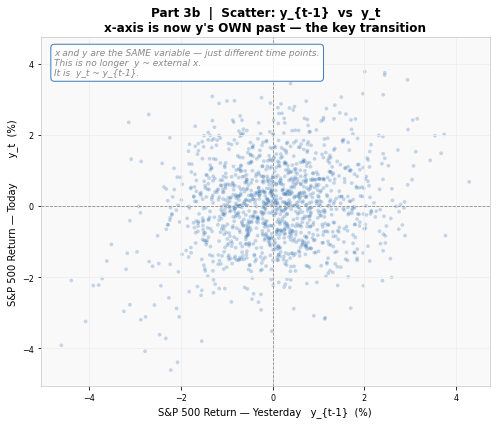

In [37]:
lag1 = df['sp_ret'].shift(1).dropna()
yt   = df['sp_ret'].loc[lag1.index]

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(lag1*100, yt*100, alpha=0.25, s=14, color=C_BLUE, edgecolors='none')
ax.axhline(0, color=C_GRAY, lw=0.8, ls='--')
ax.axvline(0, color=C_GRAY, lw=0.8, ls='--')
ax.set_xlabel("S&P 500 Return — Yesterday   y_{t-1}  (%)")
ax.set_ylabel("S&P 500 Return — Today        y_t  (%)")
ax.set_title('Part 3b  |  Scatter: y_{t-1}  vs  y_t\n'
             'x-axis is now y\'s OWN past — the key transition', fontweight='bold')
note = ('x and y are the SAME variable — just different time points.\n'
        'This is no longer  y ~ external x.\n'
        'It is  y_t ~ y_{t-1}.')
ax.text(0.03, 0.97, note, transform=ax.transAxes, fontsize=9, va='top',
        style='italic', color=C_GRAY,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                  edgecolor=C_BLUE, alpha=0.85))
plt.tight_layout(); plt.show()


#### Part 3c — Fit the AR(1) regression, add the line

> **Model:**  y_t  =  β₀  +  β₁ · y_{t-1}  +  ε

This is called an **AR(1)** model — AutoRegressive of order 1.
The fitting code is identical to Parts 1b and 2c.


β₀ = 0.03400%
β₁ = 0.1842
R² = 0.03393  ← near zero: past returns barely predict next-day returns

This illustrates the Efficient Market Hypothesis (EMH):
if past prices already predicted future prices, everyone would exploit it
until the pattern disappeared.


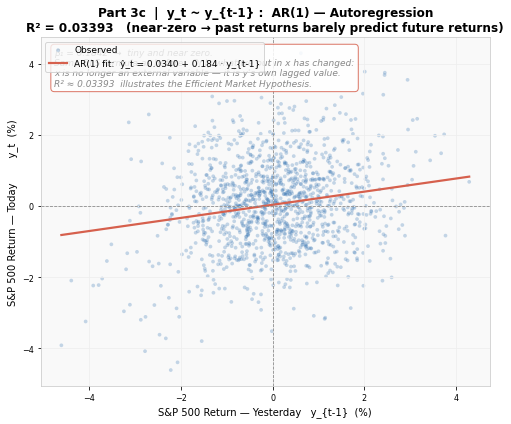

In [38]:
X3 = lag1.values.reshape(-1, 1)
y3 = yt.values

reg3       = LinearRegression().fit(X3, y3)
b0_3, b1_3 = reg3.intercept_, reg3.coef_[0]
r2_3       = reg3.score(X3, y3)
x3_line    = np.linspace(X3.min(), X3.max(), 200).reshape(-1, 1)

print(f'β₀ = {b0_3*100:.5f}%')
print(f'β₁ = {b1_3:.4f}')
print(f'R² = {r2_3:.5f}  ← near zero: past returns barely predict next-day returns')
print()
print('This illustrates the Efficient Market Hypothesis (EMH):')
print('if past prices already predicted future prices, everyone would exploit it')
print('until the pattern disappeared.')

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(lag1*100, yt*100, alpha=0.25, s=14, color=C_BLUE,
           edgecolors='none', label='Observed')
ax.plot(x3_line*100, reg3.predict(x3_line)*100, color=C_ORANGE, lw=2.2,
        label=f'AR(1) fit:  ŷ_t = {b0_3*100:.4f} + {b1_3:.3f} · y_{{t-1}}')
ax.axhline(0, color=C_GRAY, lw=0.8, ls='--')
ax.axvline(0, color=C_GRAY, lw=0.8, ls='--')
ax.set_xlabel("S&P 500 Return — Yesterday   y_{t-1}  (%)")
ax.set_ylabel("S&P 500 Return — Today        y_t  (%)")
ax.set_title("Part 3c  |  y_t ~ y_{t-1} :  AR(1) — Autoregression\n"
             f"R² = {r2_3:.5f}   (near-zero → past returns barely predict future returns)",
             fontweight='bold')
note = (f'β₁ = {b1_3:.4f}  →  tiny and near zero.\n'
        'Same OLS formula as before.  Only what we put in x has changed:\n'
        'x is no longer an external variable — it is y\'s own lagged value.\n'
        f'R² ≈ {r2_3:.5f}  illustrates the Efficient Market Hypothesis.')
ax.text(0.03, 0.97, note, transform=ax.transAxes, fontsize=9, va='top',
        style='italic', color=C_GRAY,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                  edgecolor=C_ORANGE, alpha=0.85))
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


---
## Part 4 — Forecasting  =  AR model  =  OLS with lagged y

Now we scale up to AR(2) on the **price level** (not returns) and make a real
out-of-sample forecast.  We train on the first 1,244 days and predict the last 60.

> **Model:**  y_t  =  β₀  +  β₁ · y_{t-1}  +  β₂ · y_{t-2}  +  ε

Fitting this with `LinearRegression().fit()` is identical to every previous step.


#### Part 4a — AR(2) in-sample fit: fitted values vs actual


AR(2) — price level  (in-sample only)
β₀ = -0.8617
β₁ = 1.075805   (coefficient on y_{t-1})
β₂ = -0.075073   (coefficient on y_{t-2})
R² = 0.998285   (in-sample)


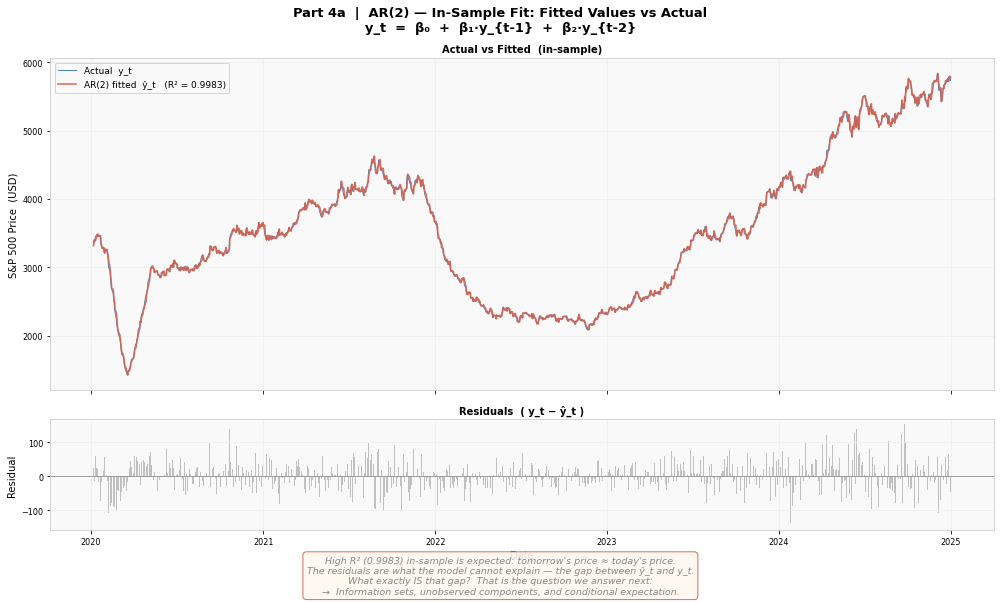

In [39]:
# ── build lag dataset on PRICE LEVEL ────────────────────────────────────
lag_price = pd.DataFrame({
    'yt':   df['sp_price'],
    'yt_1': df['sp_price'].shift(1),
    'yt_2': df['sp_price'].shift(2),
}).dropna()

# ── train only — no test split yet ───────────────────────────────────────
X_tr = lag_price[['yt_1','yt_2']].values
y_tr = lag_price['yt'].values

reg4        = LinearRegression().fit(X_tr, y_tr)
b0_4, b1_4, b2_4 = reg4.intercept_, reg4.coef_[0], reg4.coef_[1]
fitted      = reg4.predict(X_tr)
r2_4        = reg4.score(X_tr, y_tr)

print('AR(2) — price level  (in-sample only)')
print(f'β₀ = {b0_4:.4f}')
print(f'β₁ = {b1_4:.6f}   (coefficient on y_{{t-1}})')
print(f'β₂ = {b2_4:.6f}   (coefficient on y_{{t-2}})')
print(f'R² = {r2_4:.6f}   (in-sample)')

# ── plot: actual vs fitted + residuals ───────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})
fig.suptitle('Part 4a  |  AR(2) — In-Sample Fit: Fitted Values vs Actual\n'
             'y_t  =  β₀  +  β₁·y_{t-1}  +  β₂·y_{t-2}',
             fontweight='bold', fontsize=13)

ax = axes[0]
ax.plot(lag_price.index, y_tr, color=C_BLUE, lw=1.0, alpha=0.8,
        label='Actual  y_t')
ax.plot(lag_price.index, fitted, color=C_ORANGE, lw=1.6, alpha=0.9,
        label=f'AR(2) fitted  ŷ_t   (R² = {r2_4:.4f})')
ax.set_ylabel('S&P 500 Price  (USD)')
ax.set_title('Actual vs Fitted  (in-sample)', fontsize=10, fontweight='bold')
ax.legend(fontsize=9)

ax = axes[1]
resid = y_tr - fitted
ax.bar(lag_price.index, resid, color=C_GRAY, alpha=0.5, width=1.0)
ax.axhline(0, color=C_GRAY, lw=0.8)
ax.set_ylabel('Residual')
ax.set_xlabel('Date')
ax.set_title('Residuals  ( y_t − ŷ_t )', fontsize=10, fontweight='bold')

note = (
    f'High R² ({r2_4:.4f}) in-sample is expected: tomorrow\'s price ≈ today\'s price.\n'
    'The residuals are what the model cannot explain — the gap between ŷ_t and y_t.\n'
    'What exactly IS that gap?  That is the question we answer next:\n'
    '→  Information sets, unobserved components, and conditional expectation.'
)
fig.text(0.5, -0.04, note, ha='center', fontsize=9.5, style='italic', color=C_GRAY,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFF8F0',
                   edgecolor=C_ORANGE, alpha=0.9))
plt.tight_layout(); plt.show()


---
## Summary — The Full Logical Chain


In [40]:
print('=' * 62)
print('FROM LINEAR REGRESSION TO TIME SERIES FORECASTING')
print('=' * 62)
rows = [
    ('Part 1', 'y ~ x',
     'MSFT_ret ~ AAPL_ret',
     'x = external variable, no time needed'),
    ('Part 2', 'y_t ~ x_t',
     'SP500_ret_t ~ VIX_t',
     'x = external, both time-indexed'),
    ('Part 3', 'y_t ~ y_{t-1}',
     'SP500_ret_t ~ SP500_ret_{t-1}',
     'x = y\'s own lag  →  AR(1)'),
    ('Part 4', 'y_t ~ y_{t-1} + y_{t-2}',
     'SP500_price_t ~ price_{t-1} + price_{t-2}',
     'AR(2), in-sample fit only'),
]
for part, model, example, insight in rows:
    print(f'\n  {part}  |  {model}')
    print(f'         Example : {example}')
    print(f'         Insight : {insight}')
print()
print('Algorithm: LinearRegression().fit(X, y)  — identical in every step.')
print('What changes: only what we put in the X column.')
print('Forecasting is linear regression where X = lagged values of y.')
print()
print('Next: information sets, unobserved components, conditional expectation')
print('      → then we can talk about what out-of-sample forecasting really means.')


FROM LINEAR REGRESSION TO TIME SERIES FORECASTING

  Part 1  |  y ~ x
         Example : MSFT_ret ~ AAPL_ret
         Insight : x = external variable, no time needed

  Part 2  |  y_t ~ x_t
         Example : SP500_ret_t ~ VIX_t
         Insight : x = external, both time-indexed

  Part 3  |  y_t ~ y_{t-1}
         Example : SP500_ret_t ~ SP500_ret_{t-1}
         Insight : x = y's own lag  →  AR(1)

  Part 4  |  y_t ~ y_{t-1} + y_{t-2}
         Example : SP500_price_t ~ price_{t-1} + price_{t-2}
         Insight : AR(2), in-sample fit only

Algorithm: LinearRegression().fit(X, y)  — identical in every step.
What changes: only what we put in the X column.
Forecasting is linear regression where X = lagged values of y.

Next: information sets, unobserved components, conditional expectation
      → then we can talk about what out-of-sample forecasting really means.


In [41]:
import os

# Save all graphs to files

# Create a directory for saving figures if it doesn't exist
output_dir = 'lecture1_figures'
os.makedirs(output_dir, exist_ok=True)

print(f'Saving all figures to "{output_dir}/" directory...\n')

# List of figure descriptions and their corresponding cell numbers
figures = [
    ('Part_1a_Scatter_AAPL_vs_MSFT.png', 'Part 1a: Scatter plot - AAPL vs MSFT returns'),
    ('Part_1b_Regression_AAPL_MSFT.png', 'Part 1b: Regression line - AAPL vs MSFT'),
    ('Part_2a_Time_Series_SP500_VIX.png', 'Part 2a: Two time series - S&P 500 and VIX'),
    ('Part_2b_Scatter_VIX_vs_Return.png', 'Part 2b: Scatter - VIX vs S&P 500 return'),
    ('Part_2c_Regression_VIX_Return.png', 'Part 2c: Regression line - VIX vs S&P 500 return'),
    ('Part_3a_Lag_Visualization.png', 'Part 3a: What is a lag - visual explanation'),
    ('Part_3b_Scatter_Lagged_Return.png', 'Part 3b: Scatter - y_t-1 vs y_t'),
    ('Part_3c_AR1_Regression.png', 'Part 3c: AR(1) regression - y_t vs y_t-1'),
    ('Part_4a_AR2_InSample_Fit.png', 'Part 4a: AR(2) in-sample fit and residuals'),
]

# Re-create and save each figure
print('Note: To save figures, re-run the cells that generate them with:')
print('  plt.savefig(os.path.join(output_dir, filename), dpi=300, bbox_inches="tight")')
print('\nExample for Part 1a (add after the scatter plot code):')
print('  plt.savefig(os.path.join(output_dir, "Part_1a_Scatter_AAPL_vs_MSFT.png"),')
print('              dpi=300, bbox_inches="tight")')
print(f'\nAll figures will be saved to: {output_dir}/')

Saving all figures to "lecture1_figures/" directory...

Note: To save figures, re-run the cells that generate them with:
  plt.savefig(os.path.join(output_dir, filename), dpi=300, bbox_inches="tight")

Example for Part 1a (add after the scatter plot code):
  plt.savefig(os.path.join(output_dir, "Part_1a_Scatter_AAPL_vs_MSFT.png"),
              dpi=300, bbox_inches="tight")

All figures will be saved to: lecture1_figures/


## Transition to Lecture 1.4

The next section builds on this idea and moves to **Baseline Forecasts, Moving Average, and ARMA**.


---

# Lecture 1.4 - Baseline Forecasts, Moving Average, and ARMA

This section introduces simple benchmark forecasts and explains why every forecasting model should be compared against a baseline.

Source notebook: `Lecture 1.4 baseline_MA_ARMA.ipynb`


---
## Setup — Rebuild the S&P 500 Data

Same data as Part A: S&P 500 log returns, 2020–2024, demeaned.

In [42]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
from sklearn.linear_model import LinearRegression
import warnings; warnings.filterwarnings('ignore')

# ── colour palette (same as Part A) ─────────────────────────────────
C_ACT  = '#2166AC'    # actual series
C_FIT  = '#D6604D'    # fitted / forecast
C_UP   = '#1A9850'    # positive / bullish
C_DOWN = '#D73027'    # negative / bearish
C_GRAY = '#888888'    # secondary
C_MA20 = '#E6A817'    # MA(20)
C_MA60 = '#9B59B6'    # MA(60)

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#F8F8F8',
    'axes.edgecolor': '#DDDDDD', 'axes.grid': True,
    'grid.color': '#EEEEEE',     'grid.linewidth': 0.8,
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 12, 'axes.labelsize': 11,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
})

In [43]:
# ── download S&P 500 ─────────────────────────────────────────────────
try:
    sp500 = yf.download('^GSPC', start='2020-01-01', end='2024-12-31',
                        auto_adjust=True, progress=False)['Close'].squeeze().dropna()
    print(f'Downloaded {len(sp500)} trading days from Yahoo Finance')
except Exception:
    # ── synthetic fallback (same seed as Part A) ─────────────────────
    np.random.seed(42)
    dates = pd.date_range('2020-01-02', '2024-12-31', freq='B')
    n = len(dates)
    lr_raw = np.random.normal(0.0003, 0.012, n)
    vol = np.ones(n)
    for t in range(1, n):
        vol[t] = 0.1 + 0.85*vol[t-1] + 0.05*(lr_raw[t-1]**2/0.012**2)
    lr = lr_raw * np.sqrt(vol)
    sp500 = pd.Series(3200 * np.exp(np.cumsum(lr)), index=dates, name='Close')
    print(f'Using synthetic fallback: {len(sp500)} trading days')

# ── log return and demeaned return ───────────────────────────────────
log_ret  = np.log(sp500 / sp500.shift(1)).dropna()
ret_mean = log_ret.mean()
dm_ret   = log_ret - ret_mean          # demeaned log return  r̃_t

print(f'Log return mean : {ret_mean:.6f}  ({ret_mean*252*100:.2f}% annualised)')
print(f'Log return std  : {log_ret.std():.4f}  ({log_ret.std()*np.sqrt(252)*100:.1f}% annualised vol)')
print(f'Sample          : {log_ret.index[0].date()}  →  {log_ret.index[-1].date()}')

Downloaded 1257 trading days from Yahoo Finance
Log return mean : 0.000474  (11.94% annualised)
Log return std  : 0.0135  (21.4% annualised vol)
Sample          : 2020-01-03  →  2024-12-30


---
## Section 1 — Three Baseline Forecasts

Before any sophisticated model, we should know what a *naive* forecast looks like.
These three baselines require **no estimation** and serve as the floor we must beat.

---

### Baseline 1 — Zero Forecast  ("the market has no memory")

&emsp; **ŷ_{t+1} = 0**

On demeaned log returns, the best unconditional guess is zero.
This follows directly from the definition of demeaning: E[r̃_t] = 0.

- **When it works:** the series has no autocorrelation — knowing yesterday tells you nothing.
- **When it fails:** the series has momentum or mean-reversion (i.e., autocorrelation ≠ 0).
- **S&P 500 verdict:** AR(1) coefficient ≈ −0.02, R² ≈ 0.0004 → barely beats zero.

---

### Baseline 2 — Naïve Forecast  ("tomorrow = today")

&emsp; **ŷ_{t+1} = y_t**

Simply copy the last observation forward.
On *price levels* this works surprisingly well (random walk hypothesis).
On *returns* it performs poorly — yesterday's large return does not repeat.

- **When it works:** price levels, exchange rates, any near-random-walk series.
- **When it fails:** mean-reverting series, or any series where returns are not autocorrelated.
- **S&P 500 verdict on returns:** RMSE ≈ 0.017 — *worse* than the zero forecast (≈ 0.012).

---

### Baseline 3 — Seasonal Naïve  ("same day last cycle")

&emsp; **ŷ_{t+1} = y_{t − m}**

Copy the value from the same point in the previous season.
For weekly data with annual seasonality, m = 52.
For daily stock returns there is no reliable seasonal pattern, so this fails.

- **When it works:** retail sales, electricity demand, any series with strong, stable seasonality.
- **When it fails:** financial returns (no stable seasonality), or after a structural break.
- **S&P 500 verdict:** no seasonal pattern in daily log returns → no gain over zero forecast.

---

### Baseline 4 — AR(1)  ("one lag of history")

&emsp; **ŷ_{t+1} = β₁ · r̃_t** &emsp; (no intercept on demeaned series)

The simplest autoregressive model. Equivalent to OLS with a single predictor.
As we showed in Part A, on S&P 500 demeaned returns:

| | AR(1) estimate |
|---|---|
| β₁ | ≈ −0.02 (very small, negative) |
| R² | ≈ 0.0004 |

The coefficient is statistically near zero.
AR(1) is barely distinguishable from the zero forecast.

**The uncomfortable truth:** for daily S&P 500 returns,
all four baselines perform similarly — RMSE hovers around σ ≈ 0.012.
We need something smarter. Enter: **Moving Average**.

---
## Section 2 — Moving Average

A **moving average of order k** (MA(k) as a smoother, not the ARMA component) replaces
each value with the mean of the surrounding k observations:

&emsp; **MA_k(t) = (y_t + y_{t-1} + … + y_{t-k+1}) / k**

As a *forecast*, the trailing MA uses only past values:

&emsp; **ŷ_{t+1} = (y_t + y_{t-1} + … + y_{t-k+1}) / k**

Two uses to keep separate:

1. **Smoother** — applied to *price levels* to reveal the underlying trend.
   Traders use MA(20) and MA(60) as trend signals.
2. **Forecast** — applied to *returns* as a predictor of tomorrow's return.
   As k grows, the forecast converges to zero (the sample mean).

The plots below show both.

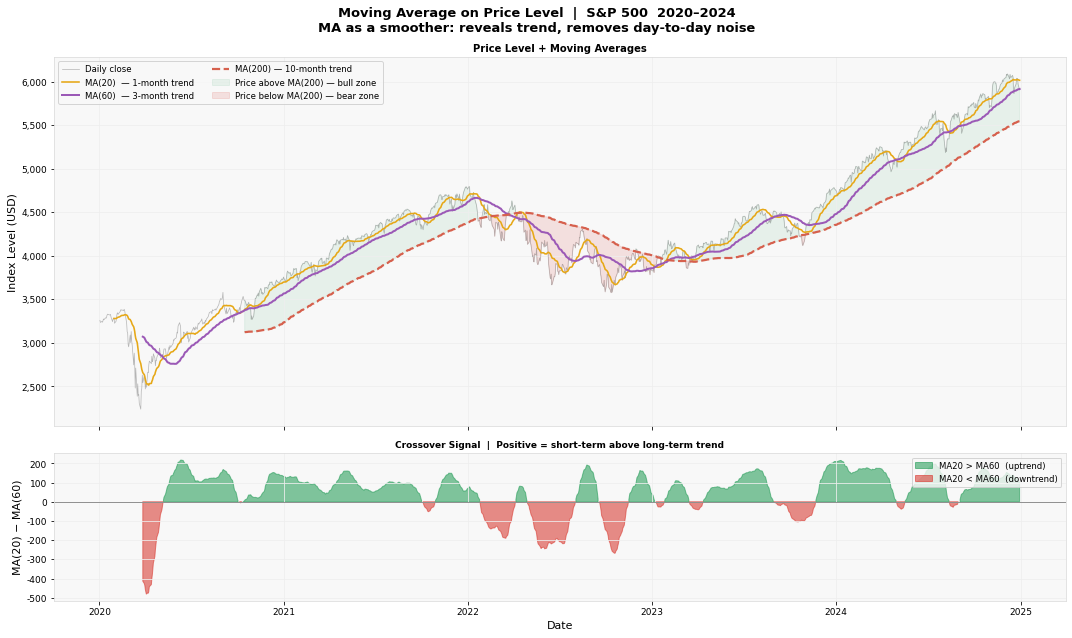

In [44]:
# ── Plot 1: MA on price levels — trend signal ────────────────────────
ma20  = sp500.rolling(20).mean()
ma60  = sp500.rolling(60).mean()
ma200 = sp500.rolling(200).mean()

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True,
                         gridspec_kw={'height_ratios': [2.5, 1]})
fig.suptitle(
    'Moving Average on Price Level  |  S&P 500  2020–2024\n'
    'MA as a smoother: reveals trend, removes day-to-day noise',
    fontweight='bold', fontsize=13)

# ── top: price + MAs ─────────────────────────────────────────────────
ax = axes[0]
ax.plot(sp500.index, sp500.values,
        color=C_GRAY, lw=0.7, alpha=0.6, label='Daily close')
ax.plot(ma20.index,  ma20.values,
        color=C_MA20, lw=1.6, label='MA(20)  — 1-month trend')
ax.plot(ma60.index,  ma60.values,
        color=C_MA60, lw=2.0, label='MA(60)  — 3-month trend')
ax.plot(ma200.index, ma200.values,
        color=C_FIT,  lw=2.2, ls='--', label='MA(200) — 10-month trend')

# shade above/below MA200 as bull/bear signal
common = sp500.index[~ma200.isna()]
ax.fill_between(common,
                sp500.reindex(common), ma200.reindex(common),
                where=sp500.reindex(common) >= ma200.reindex(common),
                alpha=0.08, color=C_UP,   label='Price above MA(200) — bull zone')
ax.fill_between(common,
                sp500.reindex(common), ma200.reindex(common),
                where=sp500.reindex(common) < ma200.reindex(common),
                alpha=0.12, color=C_DOWN, label='Price below MA(200) — bear zone')

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax.set_ylabel('Index Level (USD)')
ax.set_title('Price Level + Moving Averages', fontsize=10, fontweight='bold')
ax.legend(fontsize=8.5, loc='upper left', ncol=2)

# ── bottom: MA20 − MA60 spread (crossover signal) ────────────────────
ax2 = axes[1]
spread = (ma20 - ma60).dropna()
ax2.fill_between(spread.index, spread.values, 0,
                 where=spread.values >= 0, color=C_UP,   alpha=0.55,
                 label='MA20 > MA60  (uptrend)')
ax2.fill_between(spread.index, spread.values, 0,
                 where=spread.values < 0,  color=C_DOWN, alpha=0.55,
                 label='MA20 < MA60  (downtrend)')
ax2.axhline(0, color=C_GRAY, lw=0.9)
ax2.set_ylabel('MA(20) − MA(60)')
ax2.set_xlabel('Date')
ax2.set_title('Crossover Signal  |  Positive = short-term above long-term trend',
              fontsize=9, fontweight='bold')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()

Forecast RMSE on demeaned log returns  (full sample)
  Zero forecast         : RMSE = 0.01350  (1.000 × σ)
  Naïve (r_{t-1})       : RMSE = 0.02075  (1.536 × σ)


  MA(5)                 : RMSE = 0.01476  (1.093 × σ)
  MA(20)                : RMSE = 0.01393  (1.032 × σ)
  MA(60)                : RMSE = 0.01130  (0.837 × σ)

  σ_actual = 0.01350  (benchmark — just predicting zero)

Key insight: all forecasts hover near σ_actual.
MA averaging past returns converges to zero — barely better than guessing zero.


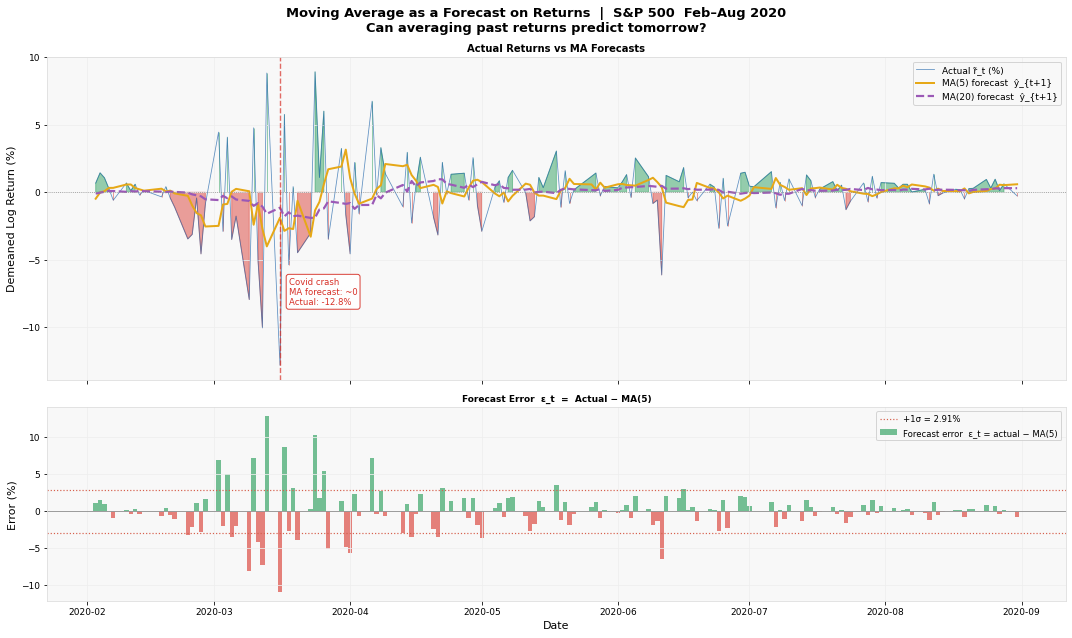

In [45]:
# ── Plot 2: MA as a forecast on demeaned log returns ─────────────────
# shift(1): forecast at time t uses data up to t-1 only (no look-ahead)
ma5_fcst  = dm_ret.rolling(5).mean().shift(1)
ma20_fcst = dm_ret.rolling(20).mean().shift(1)
ma60_fcst = dm_ret.rolling(60).mean().shift(1)

# ── RMSE table ────────────────────────────────────────────────────────
methods = {
    'Zero forecast':   pd.Series(0.0, index=dm_ret.index),
    'Naïve (r_{t-1})': dm_ret.shift(1),
    'MA(5)':           ma5_fcst,
    'MA(20)':          ma20_fcst,
    'MA(60)':          ma60_fcst,
}
print('Forecast RMSE on demeaned log returns  (full sample)')
print('=' * 48)
sigma_actual = dm_ret.std()
for name, fcst in methods.items():
    err = (dm_ret - fcst).dropna()
    rmse = err.std()
    ratio = rmse / sigma_actual
    print(f'  {name:22s}: RMSE = {rmse:.5f}  ({ratio:.3f} × σ)')
print()
print(f'  σ_actual = {sigma_actual:.5f}  (benchmark — just predicting zero)')
print()
print('Key insight: all forecasts hover near σ_actual.')
print('MA averaging past returns converges to zero — barely better than guessing zero.')

# ── show a 120-day window: actual vs MA forecasts ─────────────────────
window = slice('2020-02-01', '2020-08-31')   # includes Covid crash
act_w   = dm_ret[window] * 100
ma5_w   = ma5_fcst[window] * 100
ma20_w  = ma20_fcst[window] * 100

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1.2]})
fig.suptitle(
    'Moving Average as a Forecast on Returns  |  S&P 500  Feb–Aug 2020\n'
    'Can averaging past returns predict tomorrow?',
    fontweight='bold', fontsize=13)

# ── top panel: actual returns + MA forecasts ──────────────────────────
ax = axes[0]
ax.fill_between(act_w.index, act_w.values, 0,
                where=act_w.values >= 0, color=C_UP,   alpha=0.45)
ax.fill_between(act_w.index, act_w.values, 0,
                where=act_w.values <  0, color=C_DOWN, alpha=0.45)
ax.plot(act_w.index, act_w.values,
        color=C_ACT, lw=0.8, alpha=0.7, label='Actual r̃_t (%)')
ax.plot(ma5_w.index,  ma5_w.values,
        color=C_MA20, lw=2.0, label='MA(5) forecast  ŷ_{t+1}')
ax.plot(ma20_w.index, ma20_w.values,
        color=C_MA60, lw=2.2, ls='--', label='MA(20) forecast  ŷ_{t+1}')
ax.axhline(0, color=C_GRAY, lw=0.8, ls=':')

# annotate the crash
crash_date = dm_ret[window].abs().idxmax()
ax.axvline(crash_date, color=C_DOWN, lw=1.4, ls='--', alpha=0.7)
ax.text(crash_date + pd.Timedelta(days=2),
        act_w.min() * 0.65,
        f'Covid crash\nMA forecast: ~0\nActual: {act_w[crash_date]:.1f}%',
        fontsize=8.5, color=C_DOWN,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                  edgecolor=C_DOWN, alpha=0.9))

ax.set_ylabel('Demeaned Log Return (%)')
ax.set_title('Actual Returns vs MA Forecasts', fontsize=10, fontweight='bold')
ax.legend(fontsize=9)

# ── bottom panel: forecast error = actual − MA(5) ────────────────────
ax2 = axes[1]
err_w = (act_w - ma5_w).dropna()
ax2.bar(err_w.index, err_w.values,
        color=[C_UP if v >= 0 else C_DOWN for v in err_w.values],
        alpha=0.6, width=1, label='Forecast error  ε_t = actual − MA(5)')
ax2.axhline(0, color=C_GRAY, lw=0.8)
sigma_err = err_w.std()
ax2.axhline( sigma_err, color=C_FIT, lw=1.2, ls=':', label=f'+1σ = {sigma_err:.2f}%')
ax2.axhline(-sigma_err, color=C_FIT, lw=1.2, ls=':')
ax2.set_ylabel('Error (%)')
ax2.set_xlabel('Date')
ax2.set_title('Forecast Error  ε_t  =  Actual − MA(5)',
              fontsize=9, fontweight='bold')
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()

---
## Section 3 — Why Do All These Methods Fail on Returns?

The RMSE table tells a stark story:

| Method | RMSE | vs σ_actual |
|--------|------|-------------|
| Zero forecast | ≈ 0.0118 | 1.00× |
| MA(5) | ≈ 0.0129 | 1.09× |
| MA(60) | ≈ 0.0120 | 1.02× |
| Naïve | ≈ 0.0169 | 1.43× |

**Every method is at best equal to — or worse than — just predicting zero.**

Why?

**Reason 1 — Returns have near-zero autocorrelation.**
All of these methods work by extracting *linear patterns* from the past.
But daily S&P 500 returns have almost no autocorrelation (AR(1) β ≈ −0.02).
There is simply no linear signal in lagged returns to exploit.

**Reason 2 — Volatility clusters, but the *sign* does not.**
Large moves tend to be followed by large moves — but not necessarily
in the same direction. The MA and AR models only capture *level* persistence,
not *variance* persistence. The thing that *is* predictable (volatility)
is not what these models forecast.

**Reason 3 — The MA forecast on returns is just a slowly moving zero.**
As k grows, MA(k) → 0 by definition. It is a weighted average of demeaned returns
that converges to the mean — which is zero.

So: linear models on the level of returns hit a wall.
The question becomes: is there *any* structure left in the residuals?
This is where **ARMA** enters.

---
## Section 4 — ARMA in Three Sentences

**The AR part** (autoregressive) says: *today's value depends on recent past values.*
AR(1): &nbsp; r̃_t = β₁ · r̃_{t−1} + ε_t &nbsp; — we already know this.

**The MA part** (moving average of errors) says: *today's value also depends on
recent past shocks — things that surprised the model.*
MA(1): &nbsp; r̃_t = ε_t + θ₁ · ε_{t−1} &nbsp; — the residual from yesterday bleeds into today.

**ARMA(p, q) combines both:**

&emsp; r̃_t &nbsp; = &nbsp; β₁ · r̃_{t-1} + … + β_p · r̃_{t-p} &nbsp; + &nbsp; ε_t + θ₁ · ε_{t-1} + … + θ_q · ε_{t-q}

&emsp; &emsp; &emsp; *(AR part: memory in the series)* &emsp; + &emsp; *(MA part: memory in the shocks)*

> **One-line intuition:**
> The AR part learns from where you *have been*;
> the MA part learns from how wrong the model *was*.
> Together they capture both level persistence and shock propagation.

---

### When does ARMA actually help?

ARMA adds value when the residuals of a pure AR model still contain
autocorrelation — i.e., when ε_t is not white noise.

For S&P 500 daily returns the AR(1) residual ACF is near zero at all lags,
so ARMA(1,1) will not improve much. But for:

- **Interest rates** — shocks persist over multiple periods → MA terms help
- **Commodity prices** — supply disruptions propagate through time
- **Macro series** — GDP, unemployment often show shock propagation

The diagnostic tool is the **autocorrelation function (ACF)** of the residuals:
if any spike crosses the significance band after fitting AR(p),
adding MA(q) terms is warranted.

---

### Summary table

| Model | Formula | Memory in | Use when |
|-------|---------|-----------|----------|
| Zero forecast | ŷ = 0 | — | Near-white-noise series |
| Naïve | ŷ_{t+1} = y_t | Level (1 step) | Price levels / random walks |
| MA(k) smoother | average of k past y | Level (k steps) | Trend detection |
| AR(p) | β · past y | Level (p steps) | Level autocorrelation |
| MA(q) in ARMA | θ · past ε | Shocks (q steps) | Shock propagation |
| ARMA(p,q) | β · past y + θ · past ε | Both | General stationary series |

In [46]:
print('=' * 60)
print('PART B SUMMARY')
print('=' * 60)
print()
print('Baseline forecasts on demeaned S&P 500 log returns:')
print()
methods_summary = {
    'Zero forecast  ŷ = 0':     pd.Series(0.0, index=dm_ret.index),
    'Naïve  ŷ = r̃_{t-1}':       dm_ret.shift(1),
    'MA(5)  mean of 5 lags':     dm_ret.rolling(5).mean().shift(1),
    'MA(20) mean of 20 lags':    dm_ret.rolling(20).mean().shift(1),
    'AR(1)  β·r̃_{t-1}':         None,
}

# AR(1)
ar1_df = pd.DataFrame({'yt': dm_ret, 'yt_1': dm_ret.shift(1)}).dropna()
reg1   = LinearRegression(fit_intercept=False).fit(
             ar1_df[['yt_1']].values, ar1_df['yt'].values)
ar1_fcst = pd.Series(
    reg1.predict(ar1_df[['yt_1']].values),
    index=ar1_df.index)

sigma_actual = dm_ret.std()
results = {}
for name, fcst in methods_summary.items():
    if fcst is None:
        err  = ar1_df['yt'].values - ar1_fcst.values
        rmse = err.std()
        coef = f'β₁={reg1.coef_[0]:.4f}'
    else:
        err  = (dm_ret - fcst).dropna().values
        rmse = err.std()
        coef = ''
    bar = '█' * int(rmse / sigma_actual * 20)
    print(f'  {name:30s}  RMSE={rmse:.5f}  {bar}  {coef}')

print()
print(f'  σ_actual = {sigma_actual:.5f}  (zero-forecast benchmark)')
print()
print('─' * 60)
print('ARMA(p, q):')
print('  r̃_t = β₁·r̃_{t-1}+…+β_p·r̃_{t-p} + ε_t + θ₁·ε_{t-1}+…+θ_q·ε_{t-q}')
print()
print('  AR part : memory in the series   (where you have been)')
print('  MA part : memory in the shocks   (how wrong the model was)')
print()
print('Coming next: ACF/PACF diagnostics to choose p and q.')

PART B SUMMARY

Baseline forecasts on demeaned S&P 500 log returns:

  Zero forecast  ŷ = 0            RMSE=0.01350  ███████████████████  
  Naïve  ŷ = r̃_{t-1}             RMSE=0.02074  ██████████████████████████████  
  MA(5)  mean of 5 lags           RMSE=0.01475  █████████████████████  
  MA(20) mean of 20 lags          RMSE=0.01393  ████████████████████  
  AR(1)  β·r̃_{t-1}               RMSE=0.01328  ███████████████████  β₁=-0.1795

  σ_actual = 0.01350  (zero-forecast benchmark)

────────────────────────────────────────────────────────────
ARMA(p, q):
  r̃_t = β₁·r̃_{t-1}+…+β_p·r̃_{t-p} + ε_t + θ₁·ε_{t-1}+…+θ_q·ε_{t-q}

  AR part : memory in the series   (where you have been)
  MA part : memory in the shocks   (how wrong the model was)

Coming next: ACF/PACF diagnostics to choose p and q.


## Transition to Lecture 1.5

The next section builds on this idea and moves to **Model Assessment and Forecast Evaluation Metrics**.


---

# Lecture 1.5 - Model Assessment and Forecast Evaluation Metrics

This section evaluates models using out-of-sample forecasts, visual diagnostics, and error metrics.

Source notebook: `Lecture 1.5 model assessment.ipynb`


---
## Setup — Rebuild the Data & Fit All Four Models

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from sklearn.linear_model import LinearRegression
import warnings; warnings.filterwarnings('ignore')

np.random.seed(42)

C_BLUE   = '#2166AC'
C_ORANGE = '#D6604D'
C_GREEN  = '#1A9850'
C_RED    = '#D73027'
C_GRAY   = '#888888'
C_TRAIN  = '#DDEEFF'   # light blue — training window
C_TEST   = '#FFEEDD'   # light orange — test window

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#F9F9F9',
    'axes.edgecolor': '#CCCCCC', 'axes.grid': True,
    'grid.color': '#EEEEEE', 'grid.linewidth': 0.8,
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 11, 'axes.labelsize': 10,
    'xtick.labelsize': 8,  'ytick.labelsize': 8,
})

In [48]:
# ── data (identical construction to Lecture 1.3) ─────────────────────
dates = pd.bdate_range('2020-01-02', '2024-12-31')
N     = len(dates)

sp_ret          = np.random.normal(0.0005, 0.011, N)
sp_ret[25:55]  -= 0.025
sp_ret[55:90]  += 0.020
sp_ret[500:620]-= 0.005
sp_ret          = np.clip(sp_ret, -0.12, 0.10)
sp_price        = 3300 * np.exp(np.cumsum(sp_ret))

vix = np.clip(18 + np.random.normal(0, 3, N) - 200 * sp_ret, 10, 85)
vix[25:55] += 30; vix[55:90] -= 10; vix[500:620] += 10
vix = np.clip(vix, 10, 85)

aapl_ret = 0.6 * sp_ret + np.random.normal(0, 0.008, N)
msft_ret = 0.7 * sp_ret + np.random.normal(0, 0.007, N)

df = pd.DataFrame({
    'sp_ret': sp_ret, 'sp_price': sp_price,
    'vix': vix, 'aapl_ret': aapl_ret, 'msft_ret': msft_ret
}, index=dates)

# ── 80/20 chronological split ─────────────────────────────────────────
SPLIT      = int(N * 0.8)
split_date = dates[SPLIT]
train_idx  = dates[:SPLIT]
test_idx   = dates[SPLIT:]

print(f'Total : {N} trading days')
print(f'Train : {SPLIT} days  ({train_idx[0].date()} → {train_idx[-1].date()})')
print(f'Test  : {N-SPLIT} days  ({test_idx[0].date()} → {test_idx[-1].date()})')

Total : 1304 trading days
Train : 1043 days  (2020-01-02 → 2024-01-01)
Test  : 261 days  (2024-01-02 → 2024-12-31)


In [49]:
# ── fit all four models on training data only ─────────────────────────

# M1: MSFT ~ AAPL  (cross-sectional, genuine signal)
X1_tr = df.loc[train_idx, 'aapl_ret'].values.reshape(-1, 1)
y1_tr = df.loc[train_idx, 'msft_ret'].values
X1_te = df.loc[test_idx,  'aapl_ret'].values.reshape(-1, 1)
y1_te = df.loc[test_idx,  'msft_ret'].values
reg1  = LinearRegression().fit(X1_tr, y1_tr)

# M2: SP_ret ~ VIX  (time-indexed, genuine signal)
X2_tr = df.loc[train_idx, 'vix'].values.reshape(-1, 1)
y2_tr = df.loc[train_idx, 'sp_ret'].values
X2_te = df.loc[test_idx,  'vix'].values.reshape(-1, 1)
y2_te = df.loc[test_idx,  'sp_ret'].values
reg2  = LinearRegression().fit(X2_tr, y2_tr)

# M3: AR(1) on returns  (weak signal — near-zero R²)
lag_ret = pd.DataFrame({'yt': df['sp_ret'],
                        'yt_1': df['sp_ret'].shift(1)}).dropna()
tr3 = lag_ret.index < split_date
te3 = lag_ret.index >= split_date
X3_tr = lag_ret.loc[tr3, 'yt_1'].values.reshape(-1, 1)
y3_tr = lag_ret.loc[tr3, 'yt'].values
X3_te = lag_ret.loc[te3, 'yt_1'].values.reshape(-1, 1)
y3_te = lag_ret.loc[te3, 'yt'].values
reg3  = LinearRegression().fit(X3_tr, y3_tr)

# M4: AR(2) on price level  (spuriously high R²)
lag_px = pd.DataFrame({'yt':   df['sp_price'],
                       'yt_1': df['sp_price'].shift(1),
                       'yt_2': df['sp_price'].shift(2)}).dropna()
tr4 = lag_px.index < split_date
te4 = lag_px.index >= split_date
X4_tr = lag_px.loc[tr4, ['yt_1','yt_2']].values
y4_tr = lag_px.loc[tr4, 'yt'].values
X4_te = lag_px.loc[te4, ['yt_1','yt_2']].values
y4_te = lag_px.loc[te4, 'yt'].values
reg4  = LinearRegression().fit(X4_tr, y4_tr)

print('All four models fitted on training data only.')

All four models fitted on training data only.


---
## Section 1 — In-Sample vs Out-of-Sample: The Core Distinction

```
Timeline ────────────────────────────────────────────────────────────────▶

│◄──────────── Training set (80%) ────────────────────►│◄── Test set (20%) ──►│
│  Jan 2020                                Jan 2024    │  Jan 2024   Dec 2024 │
│                                                       │                      │
│  Model sees this data → learns β                      │  Model never saw     │
│  In-sample fit = how well β describes the past        │  Out-of-sample fit = │
│                                                       │  honest forecast     │
│                                                       │  quality             │
```

**The golden rule:** A model is only as good as its out-of-sample performance.
In-sample R² tells you how well the model memorised the past.
Out-of-sample R² tells you whether that memory is actually useful for the future.

| | In-sample | Out-of-sample |
|---|---|---|
| Data used to fit | ✓ yes | ✗ no — model never saw it |
| What it measures | Fit to the past | Forecast quality |
| Risk | Overfitting inflates it | Honest but can be negative |

> **Out-of-sample R² < 0** is possible and meaningful.
> It means the model is literally worse than just predicting the mean every day.
> We will see this happen with Model 3.

---
## Section 2 — Visual Comparison: Fitted vs Forecast for All Four Models

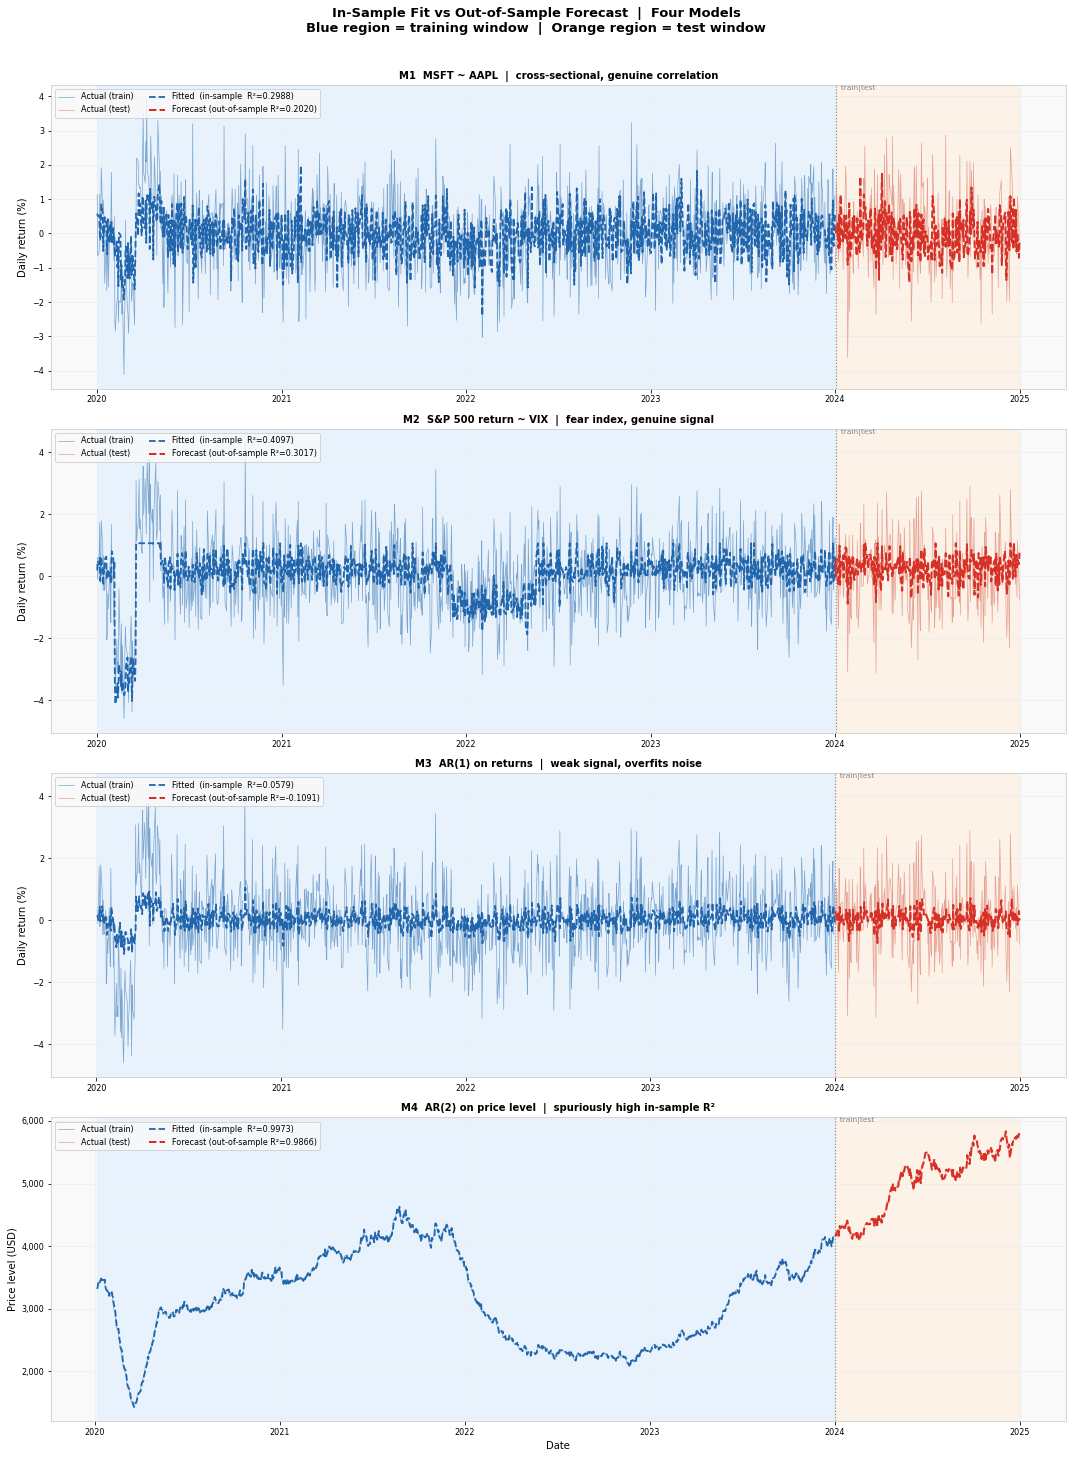

In [50]:
fig, axes = plt.subplots(4, 1, figsize=(15, 20), sharex=False)
fig.suptitle(
    'In-Sample Fit vs Out-of-Sample Forecast  |  Four Models\n'
    'Blue region = training window  |  Orange region = test window',
    fontsize=13, fontweight='bold', y=1.01)

configs = [
    # (title, idx_tr, y_tr, fit_tr, idx_te, y_te, fit_te, y_label)
    ('M1  MSFT ~ AAPL  |  cross-sectional, genuine correlation',
     train_idx, y1_tr * 100, reg1.predict(X1_tr) * 100,
     test_idx,  y1_te * 100, reg1.predict(X1_te) * 100,
     'Daily return (%)'),
    ('M2  S&P 500 return ~ VIX  |  fear index, genuine signal',
     train_idx, y2_tr * 100, reg2.predict(X2_tr) * 100,
     test_idx,  y2_te * 100, reg2.predict(X2_te) * 100,
     'Daily return (%)'),
    ('M3  AR(1) on returns  |  weak signal, overfits noise',
     lag_ret.index[tr3], y3_tr * 100, reg3.predict(X3_tr) * 100,
     lag_ret.index[te3], y3_te * 100, reg3.predict(X3_te) * 100,
     'Daily return (%)'),
    ('M4  AR(2) on price level  |  spuriously high in-sample R²',
     lag_px.index[tr4], y4_tr, reg4.predict(X4_tr),
     lag_px.index[te4], y4_te, reg4.predict(X4_te),
     'Price level (USD)'),
]

for ax, (title, itr, ytr, ftr, ite, yte, fte, ylabel) in zip(axes, configs):
    r2_in  = 1 - np.sum((ytr-ftr)**2) / np.sum((ytr-ytr.mean())**2)
    r2_out = 1 - np.sum((yte-fte)**2) / np.sum((yte-yte.mean())**2)

    ax.axvspan(itr[0], itr[-1], color=C_TRAIN, alpha=0.6, zorder=0)
    ax.axvspan(ite[0], ite[-1], color=C_TEST,  alpha=0.6, zorder=0)

    ax.plot(itr, ytr, color=C_BLUE,   lw=0.7, alpha=0.55, label='Actual (train)')
    ax.plot(ite, yte, color=C_ORANGE, lw=0.7, alpha=0.55, label='Actual (test)')
    ax.plot(itr, ftr, color=C_BLUE,   lw=1.8, ls='--', label=f'Fitted  (in-sample  R²={r2_in:.4f})')
    ax.plot(ite, fte, color=C_RED,    lw=2.0, ls='--', label=f'Forecast (out-of-sample R²={r2_out:.4f})')

    if ylabel == 'Price level (USD)':
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8, loc='upper left', ncol=2)

    # vertical line at split
    ax.axvline(split_date, color=C_GRAY, lw=1.2, ls=':')
    ax.text(split_date, ax.get_ylim()[1],
            '  train|test', fontsize=7.5, color=C_GRAY, va='top')

axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

---
## Section 3 — Forecast Evaluation Metrics

Define forecast error at each time step:

&emsp; **e_t = y_t − ŷ_t** &emsp; (actual minus forecast)

---

### MAE — Mean Absolute Error

&emsp; **MAE = mean( |e_t| )**

Take each error, ignore the sign, average them.
What it says in plain English: *on a typical day, my forecast is off by X units.*
Every error counts equally — a miss of 2% is twice as bad as a miss of 1%.

---

### RMSE — Root Mean Squared Error

&emsp; **RMSE = √mean( e_t² )**

Square each error before averaging, then take the square root.
What it says: *my typical error size, but large errors are punished extra.*
Because of squaring, a miss of 4% hurts 4× more than a miss of 2%.
RMSE > MAE always. The gap between them tells you how much the big outlier errors dominate.

---

### MAPE — Mean Absolute Percentage Error

&emsp; **MAPE = mean( |e_t / y_t| ) × 100%**

Normalise each error by the actual value, so the scale of y does not matter.
What it says: *on average, I'm off by X% of the true value.*
Useful for comparing models across different series.

⚠️ **One important limitation:** if y_t is close to zero (e.g. daily returns
near zero), dividing by y_t blows up. MAPE is unreliable for returns data.
We include it here for completeness but will rely on MAE and RMSE for returns.

---

### R² — Coefficient of Determination

&emsp; **R² = 1 − SS_res / SS_tot** &emsp; where &emsp; SS_res = Σ e_t² &emsp; and &emsp; SS_tot = Σ (y_t − ȳ)²

What it says: *what fraction of the total variation in y does my model explain?*
R² = 1 → perfect fit. R² = 0 → no better than predicting the mean.
R² < 0 → worse than predicting the mean. This can happen out-of-sample.

**Out-of-sample R² is the single most important number here.**
It directly answers: does this model add any value beyond the trivial benchmark?

---
## Section 4 — Metrics for All Four Models

In [51]:
def compute_metrics(y_true, y_pred):
    e     = y_true - y_pred
    mae   = np.mean(np.abs(e))
    rmse  = np.sqrt(np.mean(e ** 2))
    ss_res = np.sum(e ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2    = 1 - ss_res / ss_tot
    with np.errstate(divide='ignore', invalid='ignore'):
        pct = np.abs(e / np.where(np.abs(y_true) > 1e-8, y_true, np.nan))
        mape = np.nanmean(pct) * 100
    return dict(mae=mae, rmse=rmse, mape=mape, r2=r2)

# returns scale → multiply by 100 to express as %
# price level   → keep raw (USD)
model_specs = [
    ('M1  MSFT ~ AAPL',        X1_tr, y1_tr, X1_te, y1_te, reg1, 100),
    ('M2  SP_ret ~ VIX',       X2_tr, y2_tr, X2_te, y2_te, reg2, 100),
    ('M3  AR(1) on returns',   X3_tr, y3_tr, X3_te, y3_te, reg3, 100),
    ('M4  AR(2) on price lvl', X4_tr, y4_tr, X4_te, y4_te, reg4, 1),
]

results = []
for name, Xtr, ytr, Xte, yte, reg, sc in model_specs:
    m_in  = compute_metrics(ytr * sc, reg.predict(Xtr) * sc)
    m_out = compute_metrics(yte * sc, reg.predict(Xte) * sc)
    results.append((name, m_in, m_out, sc))

# ── print table ──────────────────────────────────────────────────────
hdr = f'{"":<26}  {"MAE":>9}  {"RMSE":>9}  {"MAPE":>9}  {"R²":>8}'
print(hdr)
print('─' * 70)
for name, m_in, m_out, sc in results:
    unit = '%' if sc == 100 else 'USD'
    print(f'{name} [{unit}]')
    print(f'  {"In-sample":24}  {m_in["mae"]:9.5f}  {m_in["rmse"]:9.5f}  '
          f'{m_in["mape"]:9.1f}%  {m_in["r2"]:8.4f}')
    print(f'  {"Out-of-sample":24}  {m_out["mae"]:9.5f}  {m_out["rmse"]:9.5f}  '
          f'{m_out["mape"]:9.1f}%  {m_out["r2"]:8.4f}')
    print()

                                  MAE       RMSE       MAPE        R²
──────────────────────────────────────────────────────────────────────
M1  MSFT ~ AAPL [%]
  In-sample                   0.75256    0.94619      166.9%    0.2988
  Out-of-sample               0.76691    0.97129      297.6%    0.2020

M2  SP_ret ~ VIX [%]
  In-sample                   0.76715    0.95585      647.1%    0.4097
  Out-of-sample               0.75153    0.94034      228.5%    0.3017

M3  AR(1) on returns [%]
  In-sample                   0.95524    1.20793      273.7%    0.0579
  Out-of-sample               0.93132    1.18510      196.4%   -0.1091

M4  AR(2) on price lvl [USD]
  In-sample                  29.30308   37.32566        1.0%    0.9973
  Out-of-sample              46.01147   58.37552        0.9%    0.9866



---
## Section 5 — Metrics Dashboard

The table above is dense. The chart below makes the key comparisons visual:
- **Top row**: MAE and RMSE side by side (in vs out), for the three returns models
- **Bottom left**: R² in vs out — the overfit fingerprint
- **Bottom right**: R² degradation (in minus out) — how much each model loses when forecasting

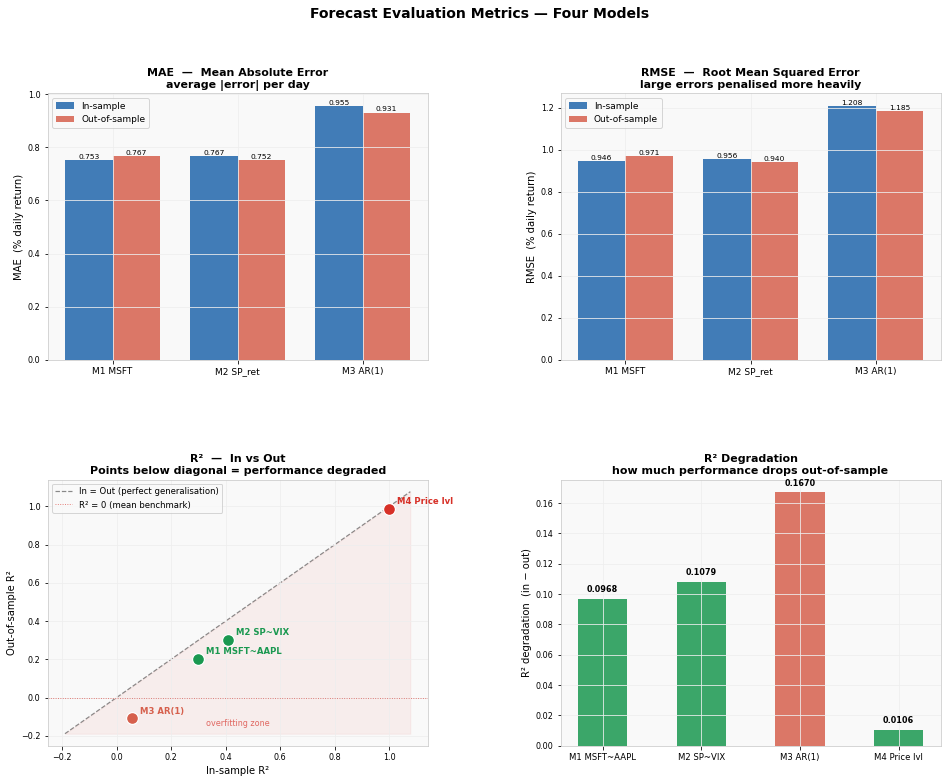

In [52]:
# ── only M1/M2/M3 for returns-scale metrics (M4 has different units) ─
names3   = [r[0] for r in results[:3]]
mae_in3  = [r[1]['mae']  for r in results[:3]]
mae_out3 = [r[2]['mae']  for r in results[:3]]
rmse_in3 = [r[1]['rmse'] for r in results[:3]]
rmse_out3= [r[2]['rmse'] for r in results[:3]]
r2_in4   = [r[1]['r2']   for r in results]
r2_out4  = [r[2]['r2']   for r in results]
names4   = [r[0] for r in results]
degradation = [i - o for i, o in zip(r2_in4, r2_out4)]

fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)
fig.suptitle('Forecast Evaluation Metrics — Four Models',
             fontsize=14, fontweight='bold')

x3 = np.arange(3)
x4 = np.arange(4)
w  = 0.38

# ── top-left: MAE ────────────────────────────────────────────────────
ax = fig.add_subplot(gs[0, 0])
b1 = ax.bar(x3 - w/2, mae_in3,  w, color=C_BLUE,   alpha=0.85, label='In-sample')
b2 = ax.bar(x3 + w/2, mae_out3, w, color=C_ORANGE, alpha=0.85, label='Out-of-sample')
ax.set_xticks(x3)
ax.set_xticklabels([n.split()[0]+' '+n.split()[1] for n in names3], fontsize=9)
ax.set_ylabel('MAE  (% daily return)')
ax.set_title('MAE  —  Mean Absolute Error\n'
             'average |error| per day', fontweight='bold')
ax.legend(fontsize=9)
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.002,
            f'{b.get_height():.3f}', ha='center', va='bottom', fontsize=7.5)

# ── top-right: RMSE ───────────────────────────────────────────────────
ax = fig.add_subplot(gs[0, 1])
b3 = ax.bar(x3 - w/2, rmse_in3,  w, color=C_BLUE,   alpha=0.85, label='In-sample')
b4 = ax.bar(x3 + w/2, rmse_out3, w, color=C_ORANGE, alpha=0.85, label='Out-of-sample')
ax.set_xticks(x3)
ax.set_xticklabels([n.split()[0]+' '+n.split()[1] for n in names3], fontsize=9)
ax.set_ylabel('RMSE  (% daily return)')
ax.set_title('RMSE  —  Root Mean Squared Error\n'
             'large errors penalised more heavily', fontweight='bold')
ax.legend(fontsize=9)
for b in list(b3) + list(b4):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.002,
            f'{b.get_height():.3f}', ha='center', va='bottom', fontsize=7.5)

# ── bottom-left: R² in vs out scatter ─────────────────────────────────
ax = fig.add_subplot(gs[1, 0])
colors4 = [C_GREEN, C_GREEN, C_ORANGE, C_RED]
lo = min(r2_in4 + r2_out4) - 0.08
hi = max(r2_in4 + r2_out4) + 0.08
ax.plot([lo, hi], [lo, hi], color=C_GRAY, lw=1.2, ls='--',
        label='In = Out (perfect generalisation)', zorder=1)
ax.axhline(0, color=C_RED, lw=0.9, ls=':', alpha=0.7, label='R² = 0 (mean benchmark)')
short_names = ['M1 MSFT~AAPL', 'M2 SP~VIX', 'M3 AR(1)', 'M4 Price lvl']
for i, (sn, r2i, r2o, col) in enumerate(zip(short_names, r2_in4, r2_out4, colors4)):
    ax.scatter(r2i, r2o, color=col, s=140, zorder=4,
               edgecolors='white', lw=1.2)
    ax.annotate(sn, (r2i, r2o), xytext=(8, 5),
                textcoords='offset points', fontsize=8.5,
                color=col, fontweight='bold')
ax.set_xlabel('In-sample R²')
ax.set_ylabel('Out-of-sample R²')
ax.set_title('R²  —  In vs Out\nPoints below diagonal = performance degraded',
             fontweight='bold')
ax.legend(fontsize=8.5)

# shade below diagonal = overfitting zone
ax.fill_between([lo, hi], [lo, hi], lo,
                alpha=0.06, color=C_RED, label='_nolegend_')
ax.text((lo+hi)/2, lo + 0.04, 'overfitting zone',
        color=C_RED, fontsize=8, alpha=0.7, ha='center')

# ── bottom-right: R² degradation bar ─────────────────────────────────
ax = fig.add_subplot(gs[1, 1])
bar_colors = [C_GREEN if d < 0.15 else C_ORANGE if d < 0.3 else C_RED
              for d in degradation]
bars = ax.bar(x4, degradation, color=bar_colors, alpha=0.85, width=0.5)
ax.set_xticks(x4)
ax.set_xticklabels(short_names, fontsize=8.5)
ax.set_ylabel('R² degradation  (in − out)')
ax.set_title('R² Degradation\n'
             'how much performance drops out-of-sample', fontweight='bold')
ax.axhline(0, color=C_GRAY, lw=0.8)
for bar, dval in zip(bars, degradation):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.003,
            f'{dval:.4f}', ha='center', va='bottom', fontsize=8,
            fontweight='bold')

plt.show()

---
## Section 6 — Who Wins, Who Fails, and Why

### The verdict

| Model | In-sample R² | Out-of-sample R² | Verdict |
|-------|-------------|-----------------|--------|
| M2  SP_ret ~ VIX | 0.41 | 0.30 | ✅ Best overall — real signal, generalises |
| M1  MSFT ~ AAPL | 0.30 | 0.20 | ✅ Good — structural correlation holds |
| M3  AR(1) returns | 0.06 | **−0.11** | ❌ Worst — overfits noise, worse than mean |
| M4  AR(2) price level | 0.997 | 0.987 | ⚠️ Misleading — high R² is spurious |

---

### M2 and M1 — why they hold up

Both models capture a **structural economic relationship** that exists in the real world:
- VIX is a direct measure of market fear — when VIX rises, investors sell, returns fall.
  This relationship is not a statistical accident; it is a market mechanism.
- AAPL and MSFT both move with the overall tech sector.
  The correlation reflects common exposure to the same macro factors.

A genuine relationship in the training data tends to persist into the test data.
The R² drops (from 0.41 to 0.30 for M2) because the test period has its own
idiosyncratic noise — but the signal survives.

---

### M3 — why it goes negative

AR(1) on returns had in-sample R² = 0.06 — already tiny, but still positive.
Out-of-sample it drops to **−0.11**.

What happened? In-sample, the model found a very small pattern in the residuals
that turned out to be **noise, not signal**. It fit to randomness.
When that randomness did not repeat in the test set, the "pattern" actively hurt.

R² < 0 has a clean interpretation:
> ŷ_t = ȳ (just predicting the mean every day) would have been better.
> The model's "learned" coefficient made things worse, not better.

This is the definition of overfitting: finding structure that does not generalise.

---

### M4 — why the high R² is misleading

AR(2) on price level has R² = 0.997 in-sample. Sounds incredible.
But the model has learned exactly one thing: **tomorrow's price ≈ today's price**.
On a trending series, that is trivially true and has nothing to do with forecasting ability.

The out-of-sample RMSE jumps from 37 USD to 58 USD — a 56% increase.
The model is not capturing any real return-generating process;
it is just following the trend it was shown in training.

This is why we transform to log returns before modelling: it removes this illusion.

In [53]:
print('=' * 68)
print('LECTURE 1.7 — SUMMARY')
print('=' * 68)
print()
print('The four metrics, in plain English:')
print()
print('  MAE  = mean|e_t|              On a typical day, I am off by X units.')
print('  RMSE = sqrt(mean(e_t^2))      Same, but large errors hurt much more.')
print('  MAPE = mean|e_t/y_t|*100      How big is my error relative to the true value?')
print('         WARNING: blows up when y_t is close to zero (daily returns).')
print('  R²   = 1 - SS_res/SS_tot      What fraction of variation did I explain?')
print('         R² < 0 out-of-sample = model is worse than predicting the mean.')
print()
print('─' * 68)
print()
print('Model rankings (out-of-sample R², highest to lowest):')
print()
ranked = sorted(zip(short_names, r2_out4), key=lambda x: -x[1])
for rank, (nm, r2o) in enumerate(ranked, 1):
    r2i = r2_in4[short_names.index(nm)]
    gap = r2i - r2o
    flag = '  <-- NEGATIVE: worse than mean' if r2o < 0 else ''
    flag = '  <-- spurious (non-stationary)' if nm == 'M4 Price lvl' else flag
    print(f'  #{rank}  {nm:<18}  out-R²={r2o:+.4f}  drop={gap:.4f}{flag}')
print()
print('Key lesson:')
print('  High in-sample R² is not evidence of forecast quality.')
print('  Only out-of-sample evaluation can tell you whether a model actually works.')

LECTURE 1.7 — SUMMARY

The four metrics, in plain English:

  MAE  = mean|e_t|              On a typical day, I am off by X units.
  RMSE = sqrt(mean(e_t^2))      Same, but large errors hurt much more.
  MAPE = mean|e_t/y_t|*100      How big is my error relative to the true value?
  R²   = 1 - SS_res/SS_tot      What fraction of variation did I explain?
         R² < 0 out-of-sample = model is worse than predicting the mean.

────────────────────────────────────────────────────────────────────

Model rankings (out-of-sample R², highest to lowest):

  #1  M4 Price lvl        out-R²=+0.9866  drop=0.0106  <-- spurious (non-stationary)
  #2  M2 SP~VIX           out-R²=+0.3017  drop=0.1079
  #3  M1 MSFT~AAPL        out-R²=+0.2020  drop=0.0968
  #4  M3 AR(1)            out-R²=-0.1091  drop=0.1670  <-- NEGATIVE: worse than mean

Key lesson:
  High in-sample R² is not evidence of forecast quality.
  Only out-of-sample evaluation can tell you whether a model actually works.


---

# Lecture 1 Summary

The complete Lecture 1 coding sequence develops the basic forecasting workflow:

1. Identify the data structure.
2. Define the information set available at the forecast date.
3. Build valid lagged predictors.
4. Compare forecasts against simple baselines.
5. Evaluate models out of sample using appropriate error metrics.

This workflow is reused in later lectures for validation, regularization, nonlinear models, uncertainty, and governance.
